PROYECTO 2: ANÁLISIS - SCALER RATES vs ACTIVIDAD SOLAR

Análisis de correlación entre Scaler Rates de Auger y Actividad Solar

PARTE 1: Cargando datos de Scaler Rates
  ✓ Archivo cargado: scalers.csv
    - Registros: 463915
    - Columnas: ['time', 'rateCorr', 'arrayFraction', 'rateUncorr', 'pressure']
    - Registros válidos: 463915
    - Rango temporal: 2005-03-30 20:52:30 - 2020-12-07 23:37:30

PARTE 2: Cargando datos de manchas solares
  ✓ Archivo cargado: SN_m_tot_V2.0.csv
    - Registros: 3326
    - Columnas: ['year', 'month', 'decimal_date', 'ssn', 'std_dev', 'observations', 'provisional']
    - Rango temporal: 1749-01-01 - 2026-02-01
    - Registros válidos después de limpieza: 3326

PARTE 3: Cargando datos de viento solar
  ✓ Archivo cargado: solar_wind_omni2_2008_2024.csv
    - Registros: 149040
    - Columnas: ['year', 'doy', 'hour', 'bsrn', 'id_imf', 'id_sw', 'n_imf', 'n_plasma', 'B_mag_avg', 'B_mag_vec', 'theta_B', 'phi_B', 'Bx_GSE', 'By_GSE', 'Bz_GSE', 'By_GSM', 'Bz_GSM',

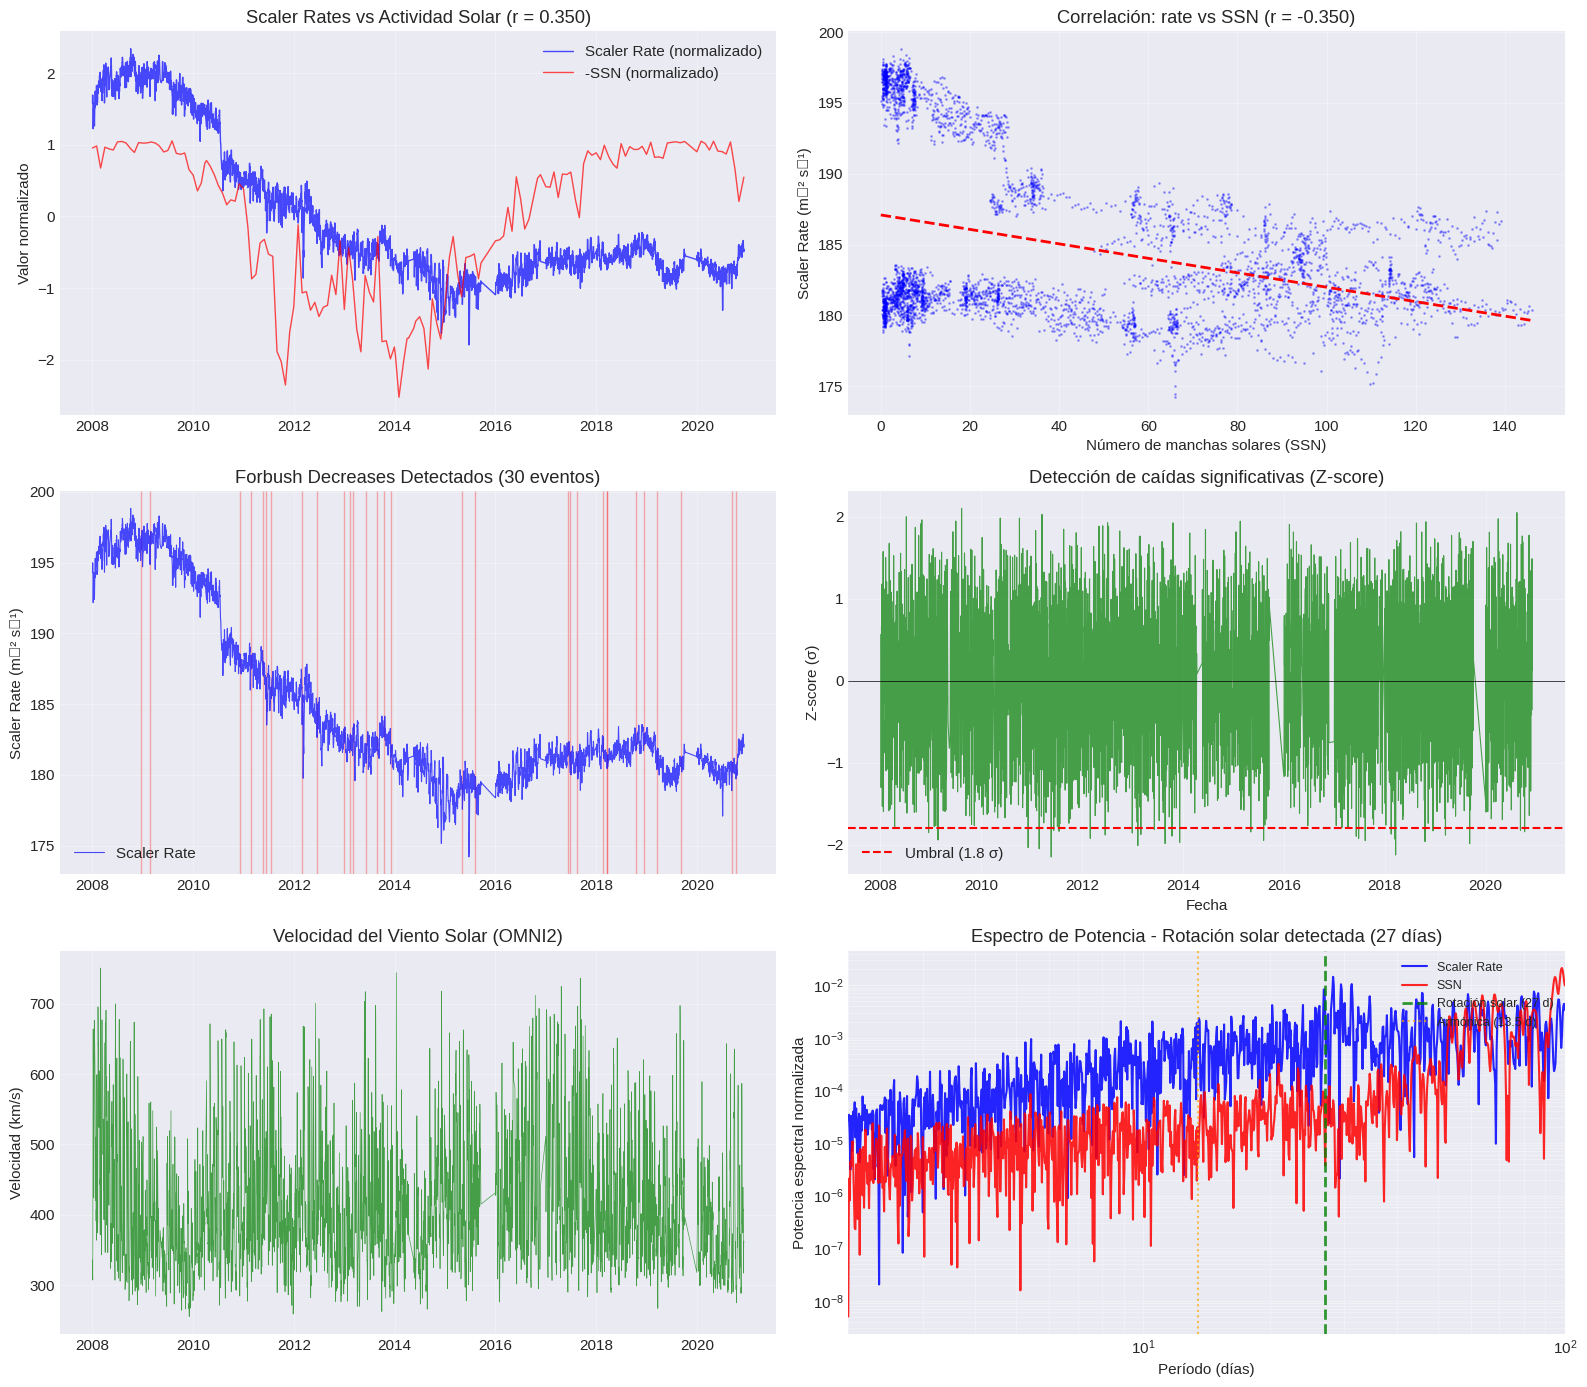


  ✓ Gráfica completa guardada en: fig_multimensajero_completo.png

PARTE 11: Gráfica de correlación cruzada


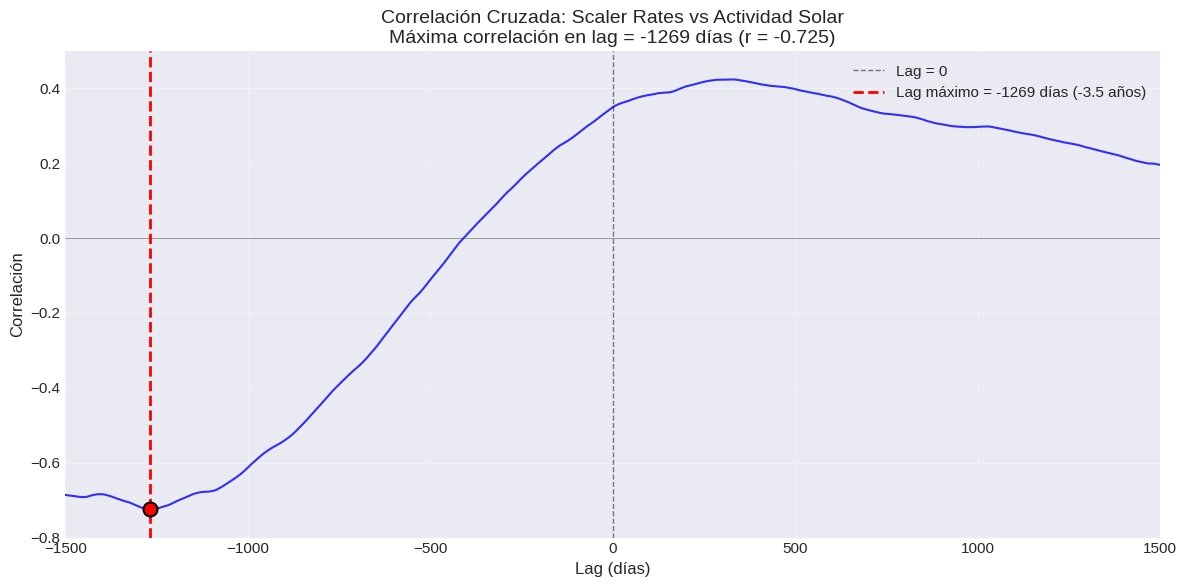

  ✓ Gráfica de correlación cruzada guardada en: fig_cross_correlation.png

PARTE 12: Análisis de autocorrelación (ACF)

  Picos locales en ACF (Scaler Rate): [np.int64(27), np.int64(41), np.int64(46), np.int64(53)] días
  Picos locales en ACF (SSN):         [] días

  Pico dominante cerca de 27 d (Scaler Rate): 27 d  (ACF = 0.301)
  Pico dominante cerca de 27 d (SSN):         20 d  (ACF = 0.705)

  IC 95% aproximado (±2/√N): ±0.0304   (N = 4315)


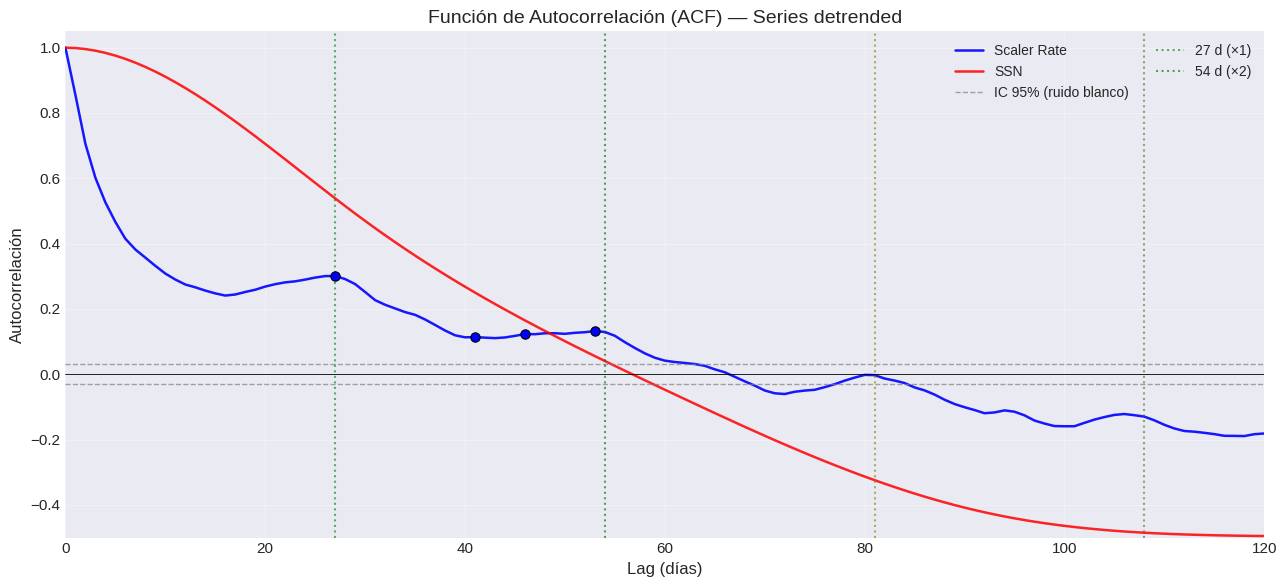


  ✓ Gráfica guardada en: fig_autocorrelacion.png


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats, signal
from datetime import datetime
import warnings
import os

warnings.filterwarnings('ignore')

# Configuración de gráficos
plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 11

print("="*70)
print("PROYECTO 2: ANÁLISIS - SCALER RATES vs ACTIVIDAD SOLAR")
print("="*70)
print("\nAnálisis de correlación entre Scaler Rates de Auger y Actividad Solar")
print("="*70)

# ============================================
# CONFIGURACIÓN DE ARCHIVOS
# ============================================
SCALER_FILE = 'scalers.csv'
SUNSPOT_FILE = 'SN_m_tot_V2.0.csv'
SOLAR_WIND_FILE = 'solar_wind_omni2_2008_2024.csv'

# ============================================
# PARTE 1: CARGAR DATOS DE SCALER RATES (AUGER)
# ============================================
print("\n" + "="*70)
print("PARTE 1: Cargando datos de Scaler Rates")
print("="*70)

def cargar_scaler_rates(filepath):
    """Carga los datos de scaler rates del Observatorio Pierre Auger"""
    try:
        df = pd.read_csv(filepath)
        print(f"  ✓ Archivo cargado: {filepath}")
        print(f"    - Registros: {len(df)}")
        print(f"    - Columnas: {list(df.columns)}")

        # Convertir tiempo Unix a datetime
        if 'time' in df.columns:
            df['datetime'] = pd.to_datetime(df['time'], unit='s')
        elif 'inc_time' in df.columns:
            df['datetime'] = pd.to_datetime(df['inc_time'], unit='s')
        else:
            raise ValueError("No se encontró columna de tiempo")

        # Identificar columna de tasa corregida
        if 'rateCorr' in df.columns:
            df.rename(columns={'rateCorr': 'rate_corr'}, inplace=True)
        elif 'rate_corr' in df.columns:
            pass
        else:
            raise ValueError("No se encontró columna de tasa")

        # Limpiar datos
        df = df[df['rate_corr'] > 0]
        print(f"    - Registros válidos: {len(df)}")
        print(f"    - Rango temporal: {df['datetime'].min()} - {df['datetime'].max()}")

        return df

    except FileNotFoundError:
        print(f"  ✗ ERROR: Archivo '{filepath}' no encontrado!")
        raise
    except Exception as e:
        print(f"  ✗ Error al cargar: {e}")
        raise

# Cargar scaler rates
df_scaler = cargar_scaler_rates(SCALER_FILE)

# ============================================
# PARTE 2: CARGAR DATOS DE MANCHAS SOLARES
# ============================================
print("\n" + "="*70)
print("PARTE 2: Cargando datos de manchas solares")
print("="*70)

def cargar_sunspot_data(filepath):
    """Carga los datos de manchas solares de SILSO (formato con punto y coma)"""
    try:
        # Leer archivo con separador punto y coma, ignorando líneas con #
        df = pd.read_csv(filepath,
                         sep=';',
                         comment='#',
                         names=['year', 'month', 'decimal_date', 'ssn', 'std_dev', 'observations', 'provisional'],
                         dtype={
                             'year': int,
                             'month': int,
                             'decimal_date': float,
                             'ssn': float,
                             'std_dev': float,
                             'observations': int,
                             'provisional': int
                         })

        print(f"  ✓ Archivo cargado: {filepath}")
        print(f"    - Registros: {len(df)}")
        print(f"    - Columnas: {list(df.columns)}")

        # Crear datetime (primer día del mes)
        df = df.dropna(subset=['year', 'month'])
        df['year'] = df['year'].astype(int)
        df['month'] = df['month'].astype(int)

        df['datetime'] = pd.to_datetime(
            df['year'].astype(str) + '-' +
            df['month'].astype(str) + '-' +
            '01',
            format='%Y-%m-%d',
            errors='coerce'
        )

        # Limpiar valores -1 (datos faltantes)
        df.loc[df['ssn'] < 0, 'ssn'] = np.nan

        # Eliminar filas con datetime inválido
        df = df.dropna(subset=['datetime'])

        print(f"    - Rango temporal: {df['datetime'].min().date()} - {df['datetime'].max().date()}")
        print(f"    - Registros válidos después de limpieza: {len(df)}")

        return df

    except FileNotFoundError:
        print(f"  ✗ ERROR: Archivo '{filepath}' no encontrado!")
        raise
    except Exception as e:
        print(f"  ✗ Error al cargar: {e}")
        raise

# Cargar manchas solares
df_ssn = cargar_sunspot_data(SUNSPOT_FILE)

# ============================================
# PARTE 3: CARGAR DATOS DE VIENTO SOLAR (OMNI2)
# ============================================
print("\n" + "="*70)
print("PARTE 3: Cargando datos de viento solar")
print("="*70)

def cargar_solar_wind(filepath):
    """Carga los datos de viento solar OMNI2"""
    try:
        df = pd.read_csv(filepath, parse_dates=['datetime'])
        print(f"  ✓ Archivo cargado: {filepath}")
        print(f"    - Registros: {len(df)}")
        print(f"    - Columnas: {list(df.columns)}")
        print(f"    - Rango temporal: {df['datetime'].min()} - {df['datetime'].max()}")

        return df

    except FileNotFoundError:
        print(f"  ✗ ERROR: Archivo '{filepath}' no encontrado!")
        raise
    except Exception as e:
        print(f"  ✗ Error al cargar: {e}")
        raise

# Cargar viento solar
df_swind = cargar_solar_wind(SOLAR_WIND_FILE)

# ============================================
# PARTE 4: RESAMPLING A RESOLUCIÓN DIARIA
# ============================================
print("\n" + "="*70)
print("PARTE 4: Procesando datos a resolución diaria")
print("="*70)

# Scaler rates: agregar a diario
df_scaler['date'] = df_scaler['datetime'].dt.date
scaler_daily = df_scaler.groupby('date').agg({
    'rate_corr': ['mean', 'std', 'count']
}).reset_index()
scaler_daily.columns = ['date', 'rate_mean', 'rate_std', 'rate_n']
scaler_daily['datetime'] = pd.to_datetime(scaler_daily['date'])
print(f"  ✓ Scaler rates diarios: {len(scaler_daily)} días")

# Viento solar: agregar a diario
df_swind['date'] = df_swind['datetime'].dt.date
swind_columns = ['V_plasma', 'N_proton', 'Bz_GSM', 'f10_7_index', 'Kp', 'Dst', 'R_sunspot']
swind_agg = {col: 'mean' for col in swind_columns if col in df_swind.columns}
swind_daily = df_swind.groupby('date').agg(swind_agg).reset_index()
swind_daily['datetime'] = pd.to_datetime(swind_daily['date'])
print(f"  ✓ Viento solar diario: {len(swind_daily)} días")

# Manchas solares: interpolación a diario
ssn_daily = df_ssn[['datetime', 'ssn']].copy()
ssn_daily.set_index('datetime', inplace=True)
ssn_daily = ssn_daily.resample('D').interpolate(method='linear').reset_index()
print(f"  ✓ Manchas solares diarias (interpoladas): {len(ssn_daily)} días")

# ============================================
# PARTE 5: COMBINAR LOS TRES DATASETS
# ============================================
print("\n" + "="*70)
print("PARTE 5: Combinando datasets")
print("="*70)

df_combined = scaler_daily.merge(ssn_daily, on='datetime', how='inner')
df_combined = df_combined.merge(swind_daily, on='datetime', how='inner')

print(f"  ✓ Datos combinados: {len(df_combined)} días")
print(f"    Rango temporal: {df_combined['datetime'].min().date()} - {df_combined['datetime'].max().date()}")

# Normalizar series
df_combined['rate_norm'] = (df_combined['rate_mean'] - df_combined['rate_mean'].mean()) / df_combined['rate_mean'].std()
df_combined['ssn_norm'] = (df_combined['ssn'] - df_combined['ssn'].mean()) / df_combined['ssn'].std()
df_combined['neg_ssn_norm'] = -df_combined['ssn_norm']

if 'V_plasma' in df_combined.columns:
    df_combined['V_norm'] = (df_combined['V_plasma'] - df_combined['V_plasma'].mean()) / df_combined['V_plasma'].std()

# ============================================
# PARTE 6: ANÁLISIS DE CORRELACIÓN
# ============================================
print("\n" + "="*70)
print("PARTE 6: Análisis de correlación")
print("="*70)

corr_pearson, p_pearson = stats.pearsonr(df_combined['rate_mean'], df_combined['ssn'])
corr_pearson_neg, p_pearson_neg = stats.pearsonr(df_combined['rate_mean'], -df_combined['ssn'])

print("\n[6.1] Correlación de Pearson:")
print(f"    rate vs SSN: r = {corr_pearson:.4f} (p = {p_pearson:.4e})")
print(f"    rate vs -SSN: r = {corr_pearson_neg:.4f} (p = {p_pearson_neg:.4e})")

corr_spearman, p_spearman = stats.spearmanr(df_combined['rate_mean'], df_combined['ssn'])
print(f"\n[6.2] Correlación de Spearman:")
print(f"    ρ = {corr_spearman:.4f} (p = {p_spearman:.4e})")

if 'V_plasma' in df_combined.columns:
    corr_wind, p_wind = stats.pearsonr(df_combined['rate_mean'], df_combined['V_plasma'])
    print(f"\n[6.3] Correlación con viento solar:")
    print(f"    rate vs V_plasma: r = {corr_wind:.4f} (p = {p_wind:.4e})")

print("\n[6.4] Interpretación:")
if p_pearson_neg < 0.05:
    print("    ✓ Correlación estadísticamente significativa")
    if abs(corr_pearson_neg) > 0.5:
        print("    ✓ Correlación fuerte (|r| > 0.5)")
    elif abs(corr_pearson_neg) > 0.3:
        print("    ✓ Correlación moderada")
    else:
        print("    ✓ Correlación débil pero significativa")
else:
    print("    ✗ Correlación no significativa estadísticamente")

# ============================================
# PARTE 7: CORRELACIÓN CRUZADA
# ============================================
print("\n" + "="*70)
print("PARTE 7: Análisis de correlación cruzada")
print("="*70)

corr_cross = signal.correlate(
    df_combined['rate_norm'] - df_combined['rate_norm'].mean(),
    -df_combined['ssn_norm'] + df_combined['ssn_norm'].mean(),
    mode='full', method='auto'
)

corr_cross_norm = corr_cross / (len(df_combined) * np.std(df_combined['rate_norm']) * np.std(-df_combined['ssn_norm']))
lags = signal.correlation_lags(len(df_combined), len(df_combined), mode='full')
max_idx = np.argmax(np.abs(corr_cross_norm))
max_lag = lags[max_idx]
max_corr = corr_cross_norm[max_idx]

print(f"\n  Lag máximo: {max_lag} días")
print(f"  Correlación en lag máximo: {max_corr:.4f}")

if max_lag > 0:
    print(f"  → Actividad solar precede a scaler rates por {max_lag} días")
elif max_lag < 0:
    print(f"  → Scaler rates preceden a actividad solar por {abs(max_lag)} días")
else:
    print(f"  → Máxima correlación en tiempo cero")

# ============================================
# PARTE 8: DETECCIÓN DE FORBUSH DECREASES (Z-SCORE)
# ============================================
print("\n" + "="*70)
print("PARTE 8: Detección de Forbush decreases (Z-score)")
print("="*70)

def detect_forbush_decreases(rate_series, datetime_series, threshold=1.8, window=7, min_duration=1):
    """Detecta Forbush decreases usando Z-score"""
    rolling_mean = rate_series.rolling(window=window, center=True).mean()
    rolling_std = rate_series.rolling(window=window, center=True).std()
    z_score = (rate_series - rolling_mean) / rolling_std
    forbush_mask = z_score < -threshold

    forbush_events = []
    in_event = False
    start_idx = None

    for i, is_forbush in enumerate(forbush_mask):
        if is_forbush and not in_event:
            in_event = True
            start_idx = i
        elif not is_forbush and in_event:
            in_event = False
            if i - start_idx >= min_duration:
                end_idx = i - 1
                rate_before = rolling_mean.iloc[start_idx] if start_idx >= 0 else rate_series.iloc[start_idx]
                rate_min = rate_series.iloc[start_idx:end_idx+1].min()
                depth_percent = (rate_before - rate_min) / rate_before * 100

                forbush_events.append({
                    'start_date': datetime_series.iloc[start_idx],
                    'end_date': datetime_series.iloc[end_idx],
                    'duration_days': (datetime_series.iloc[end_idx] - datetime_series.iloc[start_idx]).days + 1,
                    'min_rate': rate_min,
                    'depth_percent': depth_percent,
                    'min_z_score': z_score.iloc[start_idx:end_idx+1].min()
                })

    return pd.DataFrame(forbush_events), z_score

THRESHOLD = 1.8
WINDOW = 7
MIN_DURATION = 1

print(f"\n  Parámetros de detección:")
print(f"    Umbral (sigma): {THRESHOLD}")
print(f"    Ventana (días): {WINDOW}")
print(f"    Duración mínima (días): {MIN_DURATION}")

forbush_events, z_score = detect_forbush_decreases(
    df_combined['rate_mean'],
    df_combined['datetime'],
    threshold=THRESHOLD,
    window=WINDOW,
    min_duration=MIN_DURATION
)

print(f"\n  Forbush decreases detectados: {len(forbush_events)}")

if len(forbush_events) > 0:
    print(f"\n  Estadísticas de los eventos:")
    print(f"    Duración media: {forbush_events['duration_days'].mean():.1f} días")
    print(f"    Profundidad media: {forbush_events['depth_percent'].mean():.1f}%")
    print(f"    Z-score medio: {forbush_events['min_z_score'].mean():.2f} sigma")

# ============================================
# PARTE 9 (CORREGIDA): ESPECTRO DE POTENCIA - LOMB-SCARGLE
# ============================================
print("\n" + "="*70)
print("PARTE 9: Espectro de potencia (rotación solar de 27 días)")
print("="*70)

from scipy.signal import lombscargle

# --- Tiempo en días desde el inicio ---
t_days = (df_combined['datetime'] - df_combined['datetime'].min()) \
            .dt.total_seconds().values / 86400.0

rate_vals = df_combined['rate_mean'].values
ssn_vals  = df_combined['ssn'].values

# --- Detrending: quitar el ciclo solar de ~11 años (ventana ~365 d) ---
def detrend_rolling(x, window=365):
    s = pd.Series(x)
    return (s - s.rolling(window, center=True, min_periods=1).mean()).values

rate_dt = detrend_rolling(rate_vals)
ssn_dt  = detrend_rolling(ssn_vals)

# --- Grilla UNIFORME en período (log-espaciada entre 2 y 100 días) ---
periods_grid = np.logspace(np.log10(2.0), np.log10(100.0), 1000)
omega = 2 * np.pi / periods_grid          # frecuencias angulares

# --- Lomb-Scargle (maneja muestreo irregular) ---
mask_r = ~np.isnan(rate_dt)
mask_s = ~np.isnan(ssn_dt)

power_ls_rate = lombscargle(t_days[mask_r], rate_dt[mask_r], omega, normalize=True)
power_ls_ssn  = lombscargle(t_days[mask_s], ssn_dt[mask_s],  omega, normalize=True)

# --- Identificar el pico cercano a 27 días (para reporte) ---
band = (periods_grid > 20) & (periods_grid < 35)
peak_rate = periods_grid[band][np.argmax(power_ls_rate[band])]
peak_ssn  = periods_grid[band][np.argmax(power_ls_ssn[band])]
print(f"\n  Pico de potencia (Scaler Rate) cerca de 27 d: {peak_rate:.2f} días")
print(f"  Pico de potencia (SSN)         cerca de 27 d: {peak_ssn:.2f} días")

# ============================================
# PARTE 10: GENERAR TODAS LAS GRÁFICAS
# ============================================
print("\n" + "="*70)
print("PARTE 10: Generando todas las gráficas")
print("="*70)

# Crear figura con 6 subgráficas (3x2)
fig = plt.figure(figsize=(16, 14))

# 1. Serie temporal completa
ax1 = plt.subplot(3, 2, 1)
ax1.plot(df_combined['datetime'], df_combined['rate_norm'], 'b-', linewidth=1, alpha=0.7, label='Scaler Rate (normalizado)')
ax1.plot(df_combined['datetime'], df_combined['neg_ssn_norm'], 'r-', linewidth=1, alpha=0.7, label='-SSN (normalizado)')
ax1.set_ylabel('Valor normalizado')
ax1.set_title(f'Scaler Rates vs Actividad Solar (r = {corr_pearson_neg:.3f})')
ax1.legend(loc='upper right')
ax1.grid(True, alpha=0.3)

# 2. Scatter plot (correlación)
ax2 = plt.subplot(3, 2, 2)
ax2.scatter(df_combined['ssn'], df_combined['rate_mean'], c='blue', alpha=0.3, s=1)
z = np.polyfit(df_combined['ssn'], df_combined['rate_mean'], 1)
p = np.poly1d(z)
ax2.plot(df_combined['ssn'].sort_values(), p(df_combined['ssn'].sort_values()), 'r--', linewidth=2)
ax2.set_xlabel('Número de manchas solares (SSN)')
ax2.set_ylabel('Scaler Rate (m⁻² s⁻¹)')
ax2.set_title(f'Correlación: rate vs SSN (r = {corr_pearson:.3f})')
ax2.grid(True, alpha=0.3)

# 3. Forbush decreases (Z-score) - Gráfico superior: Serie con eventos
ax3 = plt.subplot(3, 2, 3)
ax3.plot(df_combined['datetime'], df_combined['rate_mean'], 'b-', linewidth=0.8, alpha=0.7, label='Scaler Rate')
if len(forbush_events) > 0:
    for _, event in forbush_events.iterrows():
        ax3.axvspan(event['start_date'], event['end_date'], alpha=0.3, color='red')
ax3.set_ylabel('Scaler Rate (m⁻² s⁻¹)')
ax3.set_title(f'Forbush Decreases Detectados ({len(forbush_events)} eventos)')
ax3.legend()
ax3.grid(True, alpha=0.3)

# 4. Forbush decreases - Gráfico inferior: Z-score
ax4 = plt.subplot(3, 2, 4)
ax4.plot(df_combined['datetime'], z_score, 'g-', linewidth=0.8, alpha=0.7)
ax4.axhline(y=-THRESHOLD, color='r', linestyle='--', linewidth=1.5, label=f'Umbral ({THRESHOLD} σ)')
ax4.axhline(y=0, color='k', linestyle='-', linewidth=0.5)
ax4.set_ylabel('Z-score (σ)')
ax4.set_xlabel('Fecha')
ax4.set_title(f'Detección de caídas significativas (Z-score)')
ax4.legend()
ax4.grid(True, alpha=0.3)

# 5. Velocidad del viento solar
ax5 = plt.subplot(3, 2, 5)
if 'V_plasma' in df_combined.columns:
    ax5.plot(df_combined['datetime'], df_combined['V_plasma'], 'g-', linewidth=0.5, alpha=0.7)
    ax5.set_ylabel('Velocidad (km/s)')
    ax5.set_title('Velocidad del Viento Solar (OMNI2)')
else:
    ax5.text(0.5, 0.5, 'Datos de viento solar no disponibles', ha='center', va='center')
ax5.grid(True, alpha=0.3)

# 6. Espectro de potencia (período de rotación solar)
ax6 = plt.subplot(3, 2, 6)
ax6.semilogy(periods_grid, power_ls_rate, 'b-', linewidth=1.5, alpha=0.85, label='Scaler Rate')
ax6.semilogy(periods_grid, power_ls_ssn,  'r-', linewidth=1.5, alpha=0.85, label='SSN')

ax6.axvline(x=27,   color='g',      linestyle='--', linewidth=2, alpha=0.8, label='Rotación solar (27 d)')
ax6.axvline(x=13.5, color='orange', linestyle=':',  linewidth=1.5, alpha=0.7, label='Armónica (13.5 d)')

ax6.set_xscale('log')
ax6.set_xlabel('Período (días)')
ax6.set_ylabel('Potencia espectral normalizada')
ax6.set_title('Espectro de Potencia - Rotación solar detectada (27 días)')
ax6.set_xlim(2, 100)
ax6.legend(loc='upper right', fontsize=9)
ax6.grid(True, alpha=0.3, which='both')

plt.tight_layout()
plt.savefig('fig_multimensajero_completo.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n  ✓ Gráfica completa guardada en: fig_multimensajero_completo.png")

# ============================================
# PARTE 11: CORRELACIÓN CRUZADA
# ============================================
print("\n" + "="*70)
print("PARTE 11: Gráfica de correlación cruzada")
print("="*70)

fig2, ax = plt.subplots(figsize=(12, 6))

ax.plot(lags, corr_cross_norm, 'b-', linewidth=1.5, alpha=0.8)
ax.axhline(y=0, color='k', linestyle='-', linewidth=0.5, alpha=0.5)
ax.axvline(x=0, color='k', linestyle='--', linewidth=1, alpha=0.5, label='Lag = 0')
ax.axvline(x=max_lag, color='r', linestyle='--', linewidth=2,
           label=f'Lag máximo = {max_lag} días ({max_lag/365.25:.1f} años)')
ax.scatter(max_lag, max_corr, color='red', s=100, zorder=5, edgecolors='black', linewidth=1.5)

ax.set_xlabel('Lag (días)', fontsize=12)
ax.set_ylabel('Correlación', fontsize=12)
ax.set_title(f'Correlación Cruzada: Scaler Rates vs Actividad Solar\n'
             f'Máxima correlación en lag = {max_lag} días (r = {max_corr:.3f})', fontsize=14)
ax.set_xlim(-1500, 1500)
ax.set_ylim(-0.8, 0.5)
ax.grid(True, alpha=0.3)
ax.legend(loc='upper right')

plt.tight_layout()
plt.savefig('fig_cross_correlation.png', dpi=150, bbox_inches='tight')
plt.show()

print("  ✓ Gráfica de correlación cruzada guardada en: fig_cross_correlation.png")

# ============================================
# PARTE 12: ANÁLISIS DE AUTOCORRELACIÓN (ACF)
# ============================================
print("\n" + "="*70)
print("PARTE 12: Análisis de autocorrelación (ACF)")
print("="*70)

from scipy.signal import find_peaks

def compute_acf(x, max_lag=120):
    """
    ACF robusta a NaN usando pares válidos (a[i], a[i+lag]).
    Usa la serie ya detrended (rate_dt, ssn_dt de la Parte 9).
    """
    x = np.asarray(x, dtype=float)
    n = len(x)
    x_c = x - np.nanmean(x)
    var = np.nanmean(x_c**2)
    acf_vals = np.full(max_lag + 1, np.nan)
    for lag in range(max_lag + 1):
        a = x_c[:n-lag]
        b = x_c[lag:]
        mask = ~(np.isnan(a) | np.isnan(b))
        if mask.sum() > 2:
            acf_vals[lag] = np.mean(a[mask] * b[mask]) / var
    return acf_vals

MAX_LAG = 120
acf_rate = compute_acf(rate_dt, MAX_LAG)
acf_ssn  = compute_acf(ssn_dt,  MAX_LAG)
lags_acf = np.arange(MAX_LAG + 1)

# --- Detectar picos locales (ignorando lag=0) ---
peaks_rate, _ = find_peaks(np.nan_to_num(acf_rate[1:]), height=0.05, distance=5)
peaks_ssn,  _ = find_peaks(np.nan_to_num(acf_ssn[1:]),  height=0.05, distance=5)
peaks_rate += 1
peaks_ssn  += 1

print(f"\n  Picos locales en ACF (Scaler Rate): {list(peaks_rate)} días")
print(f"  Picos locales en ACF (SSN):         {list(peaks_ssn)} días")

# --- Pico dominante en la banda 20–35 d ---
band = (lags_acf >= 20) & (lags_acf <= 35)
peak_27_rate = lags_acf[band][np.nanargmax(acf_rate[band])]
peak_27_ssn  = lags_acf[band][np.nanargmax(acf_ssn[band])]
print(f"\n  Pico dominante cerca de 27 d (Scaler Rate): "
      f"{peak_27_rate} d  (ACF = {acf_rate[peak_27_rate]:.3f})")
print(f"  Pico dominante cerca de 27 d (SSN):         "
      f"{peak_27_ssn} d  (ACF = {acf_ssn[peak_27_ssn]:.3f})")

# --- Intervalo de confianza aproximado (ruido blanco) ---
n_eff = len(df_combined)
ci = 2.0 / np.sqrt(n_eff)
print(f"\n  IC 95% aproximado (±2/√N): ±{ci:.4f}   (N = {n_eff})")

# ============================================
# GRÁFICA ACF
# ============================================
fig3, ax = plt.subplots(figsize=(13, 6))

ax.plot(lags_acf, acf_rate, 'b-', linewidth=1.8, alpha=0.9, label='Scaler Rate')
ax.plot(lags_acf, acf_ssn,  'r-', linewidth=1.8, alpha=0.85, label='SSN')

# Nivel de significancia
ax.axhline( ci, color='gray', linestyle='--', linewidth=1, alpha=0.7,
            label='IC 95% (ruido blanco)')
ax.axhline(-ci, color='gray', linestyle='--', linewidth=1, alpha=0.7)
ax.axhline(0,   color='k',    linewidth=0.6)

# Múltiplos de la rotación solar
for mult, color in [(1, 'green'), (2, 'darkgreen'), (3, 'olive'), (4, 'darkolivegreen')]:
    ax.axvline(27*mult, color=color, linestyle=':', linewidth=1.5, alpha=0.6,
               label=f'{27*mult} d (×{mult})' if mult <= 2 else None)

# Marcar picos detectados
ax.scatter(peaks_rate, acf_rate[peaks_rate], color='blue', s=45,
           zorder=5, edgecolors='black', linewidth=0.8)
ax.scatter(peaks_ssn,  acf_ssn[peaks_ssn],  color='red',  s=45,
           zorder=5, edgecolors='black', linewidth=0.8)

ax.set_xlabel('Lag (días)', fontsize=12)
ax.set_ylabel('Autocorrelación', fontsize=12)
ax.set_title('Función de Autocorrelación (ACF) — Series detrended', fontsize=14)
ax.set_xlim(0, MAX_LAG)
ax.set_ylim(-0.5, 1.05)
ax.grid(True, alpha=0.3)
ax.legend(loc='upper right', fontsize=10, ncol=2)

plt.tight_layout()
plt.savefig('fig_autocorrelacion.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n  ✓ Gráfica guardada en: fig_autocorrelacion.png")

PROYECTO 2: ANÁLISIS - SCALER RATES vs ACTIVIDAD SOLAR

Análisis de correlación entre Scaler Rates de Auger y Actividad Solar

PARTE 1: Cargando datos de Scaler Rates
  ✓ Archivo cargado: scalers.csv
    - Registros: 463915
    - Columnas: ['time', 'rateCorr', 'arrayFraction', 'rateUncorr', 'pressure']
    - Registros válidos: 463915
    - Rango temporal: 2005-03-30 20:52:30 - 2020-12-07 23:37:30

PARTE 2: Cargando datos de manchas solares
  ✓ Archivo cargado: SN_m_tot_V2.0.csv
    - Registros: 3326
    - Columnas: ['year', 'month', 'decimal_date', 'ssn', 'std_dev', 'observations', 'provisional']
    - Rango temporal: 1749-01-01 - 2026-02-01
    - Registros válidos después de limpieza: 3326

PARTE 3: Cargando datos de viento solar
  ✓ Archivo cargado: solar_wind_omni2_2008_2024.csv
    - Registros: 21535
    - Columnas: ['year', 'doy', 'hour', 'bsrn', 'id_imf', 'id_sw', 'n_imf', 'n_plasma', 'B_mag_avg', 'B_mag_vec', 'theta_B', 'phi_B', 'Bx_GSE', 'By_GSE', 'Bz_GSE', 'By_GSM', 'Bz_GSM', 

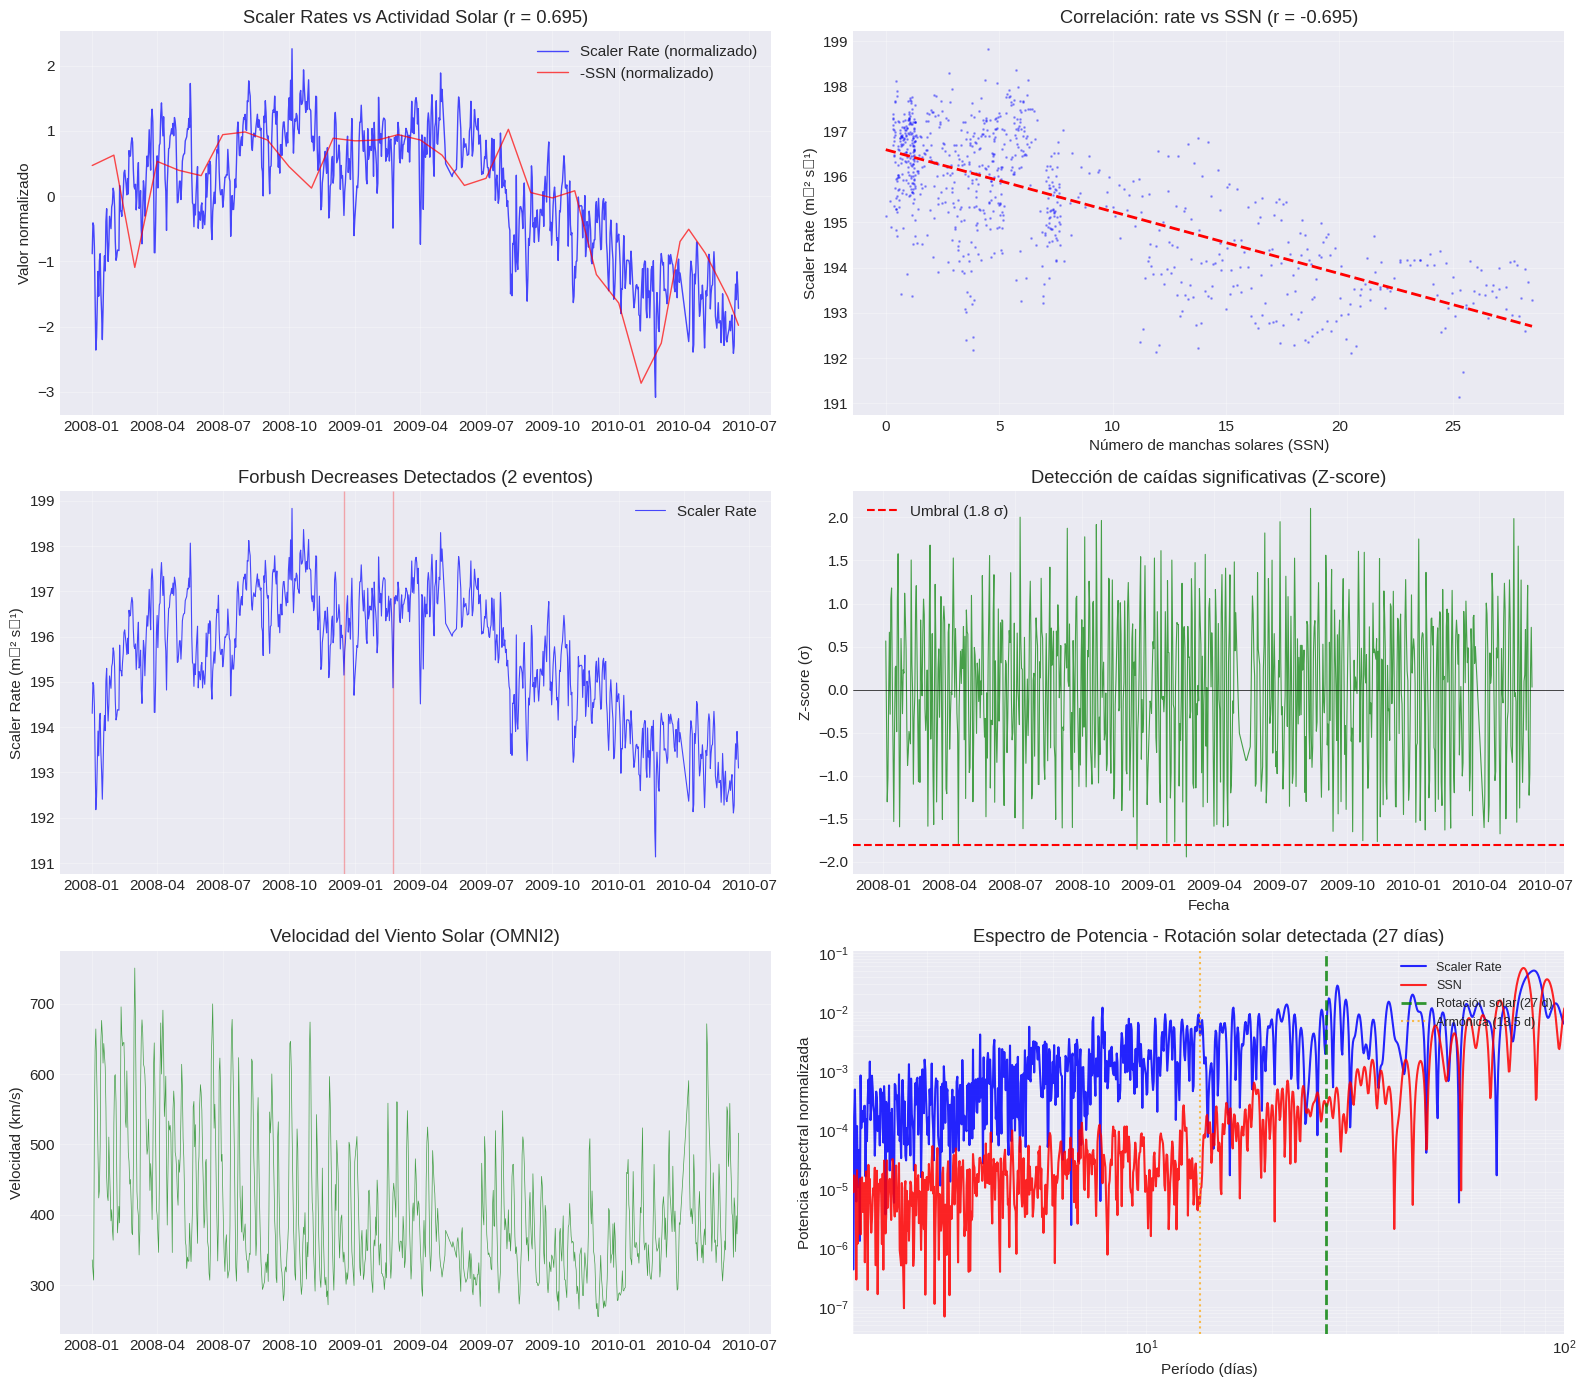


  ✓ Gráfica completa guardada en: fig_multimensajero_completo.png

PARTE 11: Gráfica de correlación cruzada


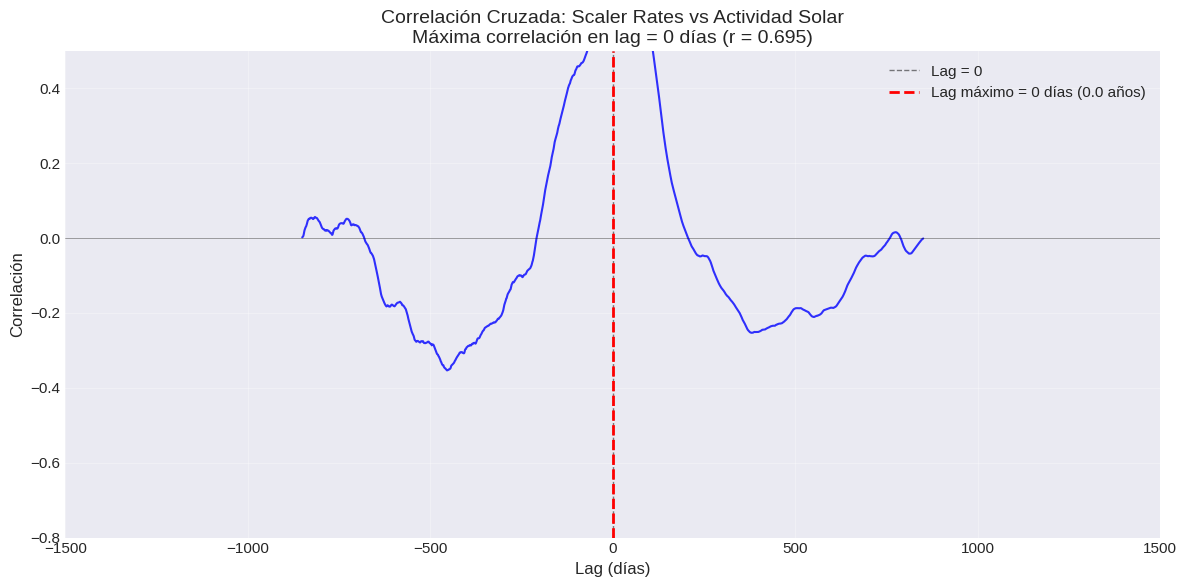

  ✓ Gráfica de correlación cruzada guardada en: fig_cross_correlation.png

PARTE 12: Análisis de autocorrelación (ACF)

  Picos locales en ACF (Scaler Rate): [np.int64(9), np.int64(15), np.int64(21), np.int64(42), np.int64(53)] días
  Picos locales en ACF (SSN):         [] días

  Pico dominante cerca de 27 d (Scaler Rate): 21 d  (ACF = 0.261)
  Pico dominante cerca de 27 d (SSN):         20 d  (ACF = 0.716)

  IC 95% aproximado (±2/√N): ±0.0685   (N = 852)


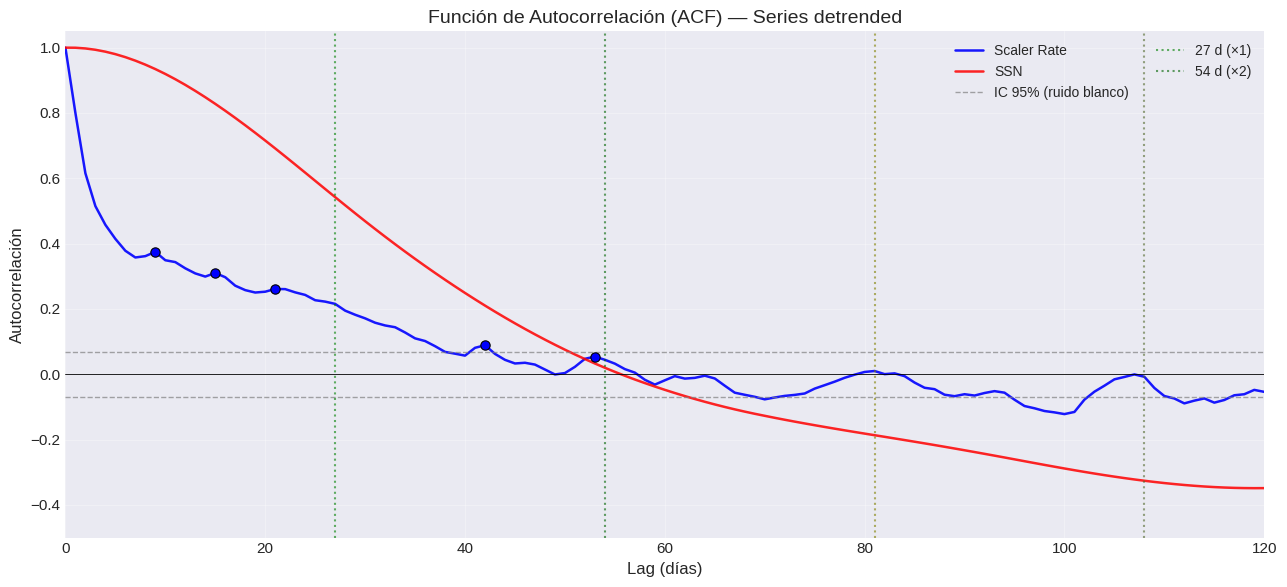


  ✓ Gráfica guardada en: fig_autocorrelacion.png

PARTE 13: Reservoir Computing (caos) para Forbush Forecast

  Dataset modelable: 822 días  |  features: 63
  Eventos Forbush (ventana +3d): 8 (0.97%)
  Train: 2008-01-30 → 2009-12-18 (657d)
  Test:  2009-12-19 → 2010-06-13 (165d)

  [Modelo 1] ESN regresión → Scaler Rate
    RMSE = 1.16 m⁻² s⁻¹   |   r = 0.4843

  [Modelo 2] ESN regresión z-score → clasificación Forbush
    AUC-ROC = nan   |   AP = 0.0000
    F1 (umbral óptimo) = 0.0000
    Matriz confusión:  TN=2  FP=113  FN=0  TP=0

  [Análisis] F1 vs horizonte de pronóstico (H días)
    H = 1 d  →  F1 = nan
    H = 2 d  →  F1 = nan
    H = 3 d  →  F1 = nan
    H = 5 d  →  F1 = nan
    H = 7 d  →  F1 = nan


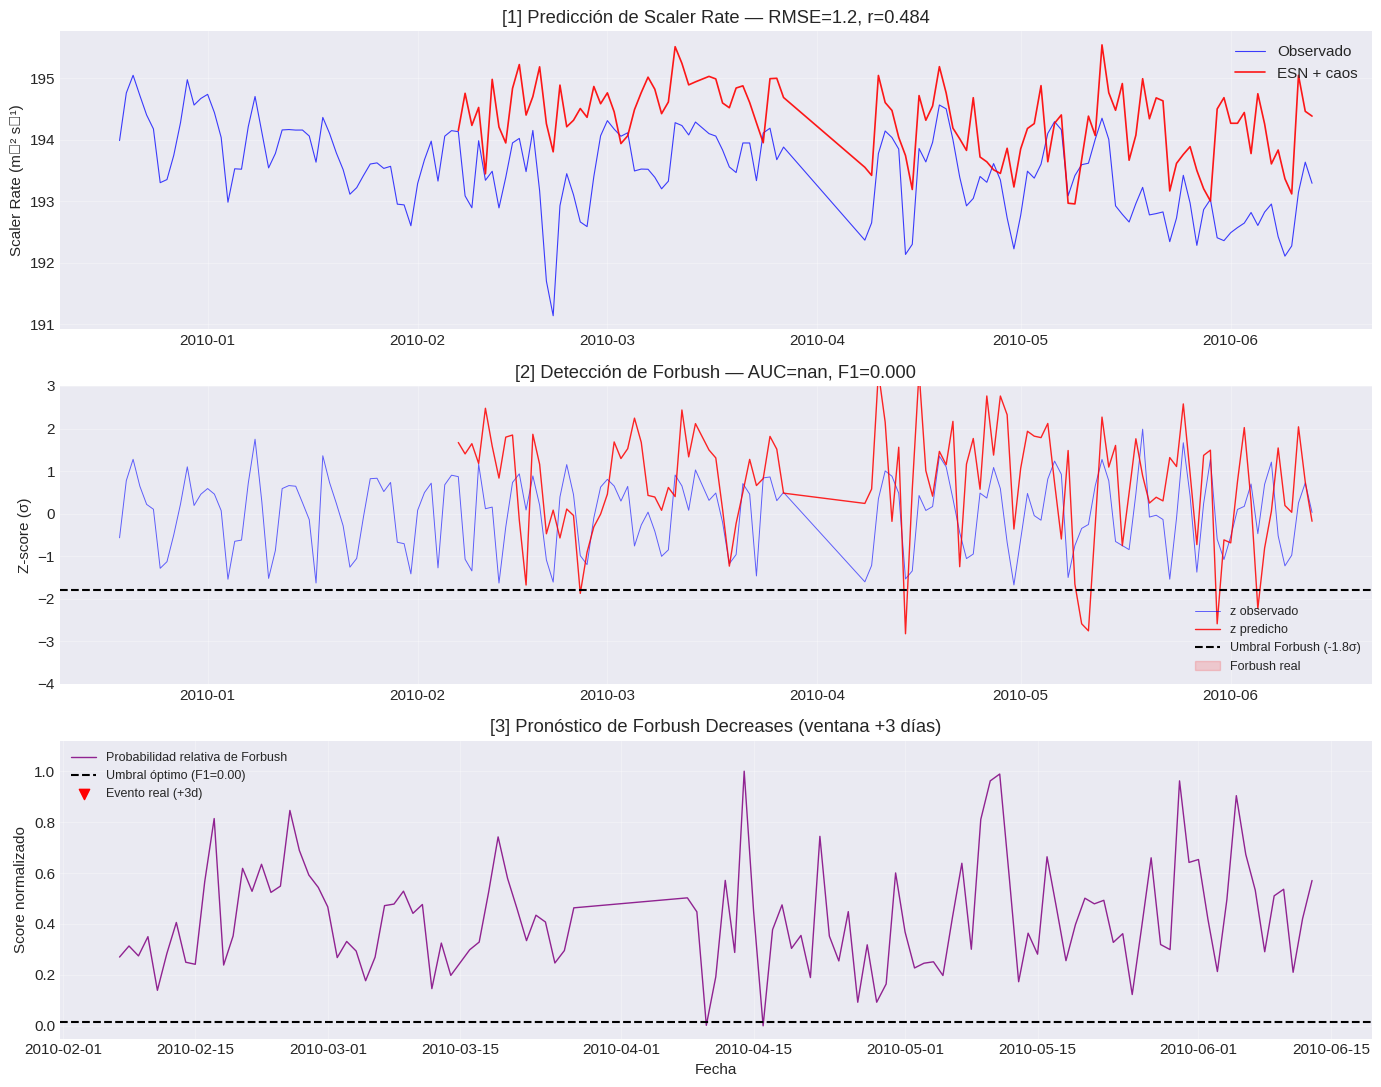


  ✓ Gráfica guardada en: fig_forbush_forecast.png

PARTE 14: Pronóstico recursivo del Scaler Rate

  Último dato de Scaler Rate:  2010-06-16
  Último dato de SSN (SILSO):  2026-02-01
  Horizonte de pronóstico:     2010-06-16 → 2026-12-31
  ⚠ SSN faltante para 333 días → relleno con persistencia del último valor

  Escenario viento solar (últimos 27 días):
    V_plasma   = 448.70
    N_proton   = 11.02
    Bz_GSM     = -0.54
    Kp         = 6.31
    Dst        = 0.00

  Dataset futuro construido: 6042 días

  Entrenando ensemble de 8 reservoirs...
  ✓ Ensemble entrenado

  Pronóstico completado para 6042 días
  Rate medio pronosticado: 196.84 m⁻² s⁻¹
  Incertidumbre media (±1σ): 0.51

  Días con señal de Forbush pronosticada: 401
  Eventos Forbush pronosticados: 14
    → 2011-09-03 a 2011-09-03
    → 2013-10-05 a 2013-10-05
    → 2019-06-25 a 2019-12-09
    → 2020-02-14 a 2020-03-11
    → 2023-06-02 a 2023-06-11
    → 2023-06-16 a 2023-07-12
    → 2024-04-29 a 2024-04-30
    → 2024-05

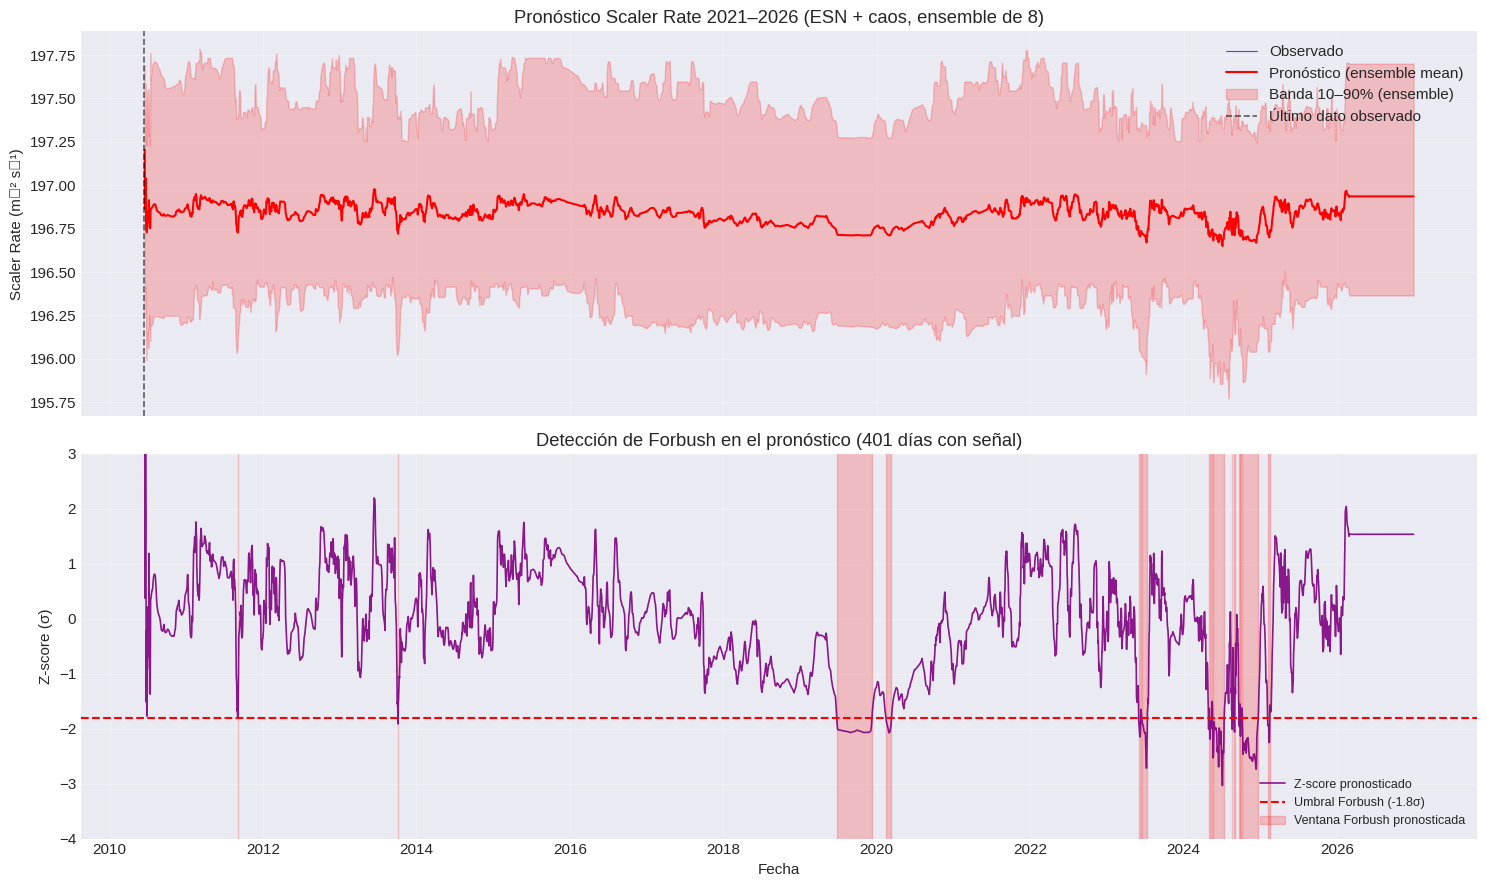


  ✓ Gráfica guardada en: fig_forecast_2021_2026.png

PARTE 15: Walk-forward validation

  Ejecutando walk-forward (esto puede tardar 1-3 minutos)...
  ✓ 0 folds completados en 0.0s

  RMSE vs Horizonte (primeros 15 días):
    H |      ESN |  Persist. |    Clim.
    1 |      nan |      0.00 |     0.00
    2 |      nan |      0.00 |     0.00
    3 |      nan |      0.00 |     0.00
    4 |      nan |      0.00 |     0.00
    5 |      nan |      0.00 |     0.00
    6 |      nan |      0.00 |     0.00
    7 |      nan |      0.00 |     0.00
    8 |      nan |      0.00 |     0.00
    9 |      nan |      0.00 |     0.00
   10 |      nan |      0.00 |     0.00
   11 |      nan |      0.00 |     0.00
   12 |      nan |      0.00 |     0.00
   13 |      nan |      0.00 |     0.00
   14 |      nan |      0.00 |     0.00
   15 |      nan |      0.00 |     0.00


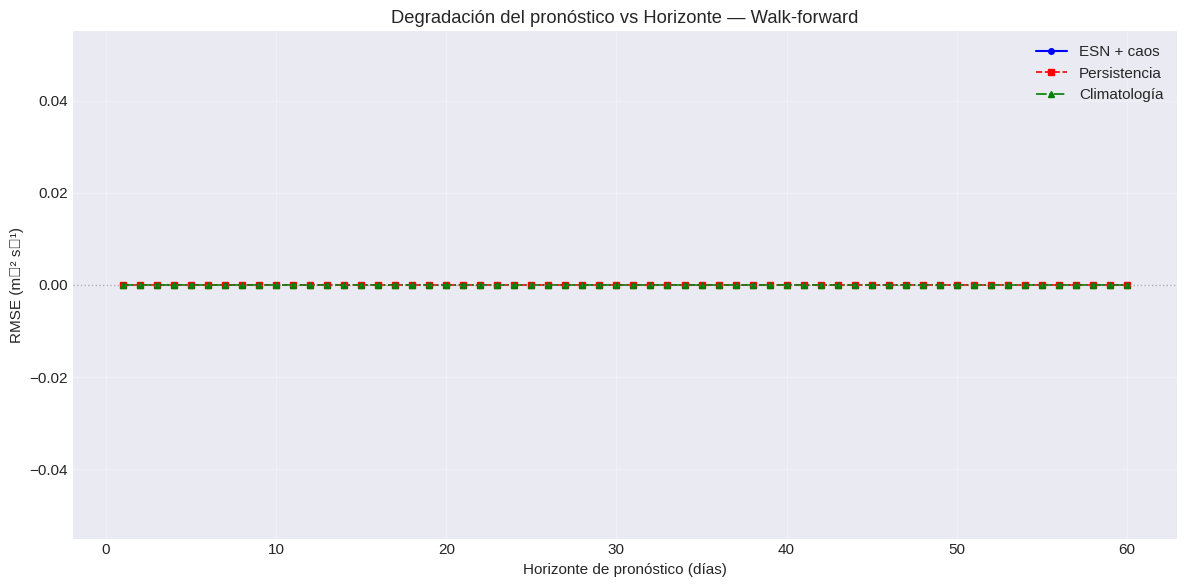

  ✓ Guardada: fig_walkforward_rmse.png


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats, signal
from datetime import datetime
import warnings
import os

warnings.filterwarnings('ignore')

# Configuración de gráficos
plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 11

print("="*70)
print("PROYECTO 2: ANÁLISIS - SCALER RATES vs ACTIVIDAD SOLAR")
print("="*70)
print("\nAnálisis de correlación entre Scaler Rates de Auger y Actividad Solar")
print("="*70)

# ============================================
# CONFIGURACIÓN DE ARCHIVOS
# ============================================
SCALER_FILE = 'scalers.csv'
SUNSPOT_FILE = 'SN_m_tot_V2.0.csv'
SOLAR_WIND_FILE = 'solar_wind_omni2_2008_2024.csv'

# ============================================
# PARTE 1: CARGAR DATOS DE SCALER RATES (AUGER)
# ============================================
print("\n" + "="*70)
print("PARTE 1: Cargando datos de Scaler Rates")
print("="*70)

def cargar_scaler_rates(filepath):
    """Carga los datos de scaler rates del Observatorio Pierre Auger"""
    try:
        df = pd.read_csv(filepath)
        print(f"  ✓ Archivo cargado: {filepath}")
        print(f"    - Registros: {len(df)}")
        print(f"    - Columnas: {list(df.columns)}")

        # Convertir tiempo Unix a datetime
        if 'time' in df.columns:
            df['datetime'] = pd.to_datetime(df['time'], unit='s')
        elif 'inc_time' in df.columns:
            df['datetime'] = pd.to_datetime(df['inc_time'], unit='s')
        else:
            raise ValueError("No se encontró columna de tiempo")

        # Identificar columna de tasa corregida
        if 'rateCorr' in df.columns:
            df.rename(columns={'rateCorr': 'rate_corr'}, inplace=True)
        elif 'rate_corr' in df.columns:
            pass
        else:
            raise ValueError("No se encontró columna de tasa")

        # Limpiar datos
        df = df[df['rate_corr'] > 0]
        print(f"    - Registros válidos: {len(df)}")
        print(f"    - Rango temporal: {df['datetime'].min()} - {df['datetime'].max()}")

        return df

    except FileNotFoundError:
        print(f"  ✗ ERROR: Archivo '{filepath}' no encontrado!")
        raise
    except Exception as e:
        print(f"  ✗ Error al cargar: {e}")
        raise

# Cargar scaler rates
df_scaler = cargar_scaler_rates(SCALER_FILE)

# ============================================
# PARTE 2: CARGAR DATOS DE MANCHAS SOLARES
# ============================================
print("\n" + "="*70)
print("PARTE 2: Cargando datos de manchas solares")
print("="*70)

def cargar_sunspot_data(filepath):
    """Carga los datos de manchas solares de SILSO (formato con punto y coma)"""
    try:
        # Leer archivo con separador punto y coma, ignorando líneas con #
        df = pd.read_csv(filepath,
                         sep=';',
                         comment='#',
                         names=['year', 'month', 'decimal_date', 'ssn', 'std_dev', 'observations', 'provisional'],
                         dtype={
                             'year': int,
                             'month': int,
                             'decimal_date': float,
                             'ssn': float,
                             'std_dev': float,
                             'observations': int,
                             'provisional': int
                         })

        print(f"  ✓ Archivo cargado: {filepath}")
        print(f"    - Registros: {len(df)}")
        print(f"    - Columnas: {list(df.columns)}")

        # Crear datetime (primer día del mes)
        df = df.dropna(subset=['year', 'month'])
        df['year'] = df['year'].astype(int)
        df['month'] = df['month'].astype(int)

        df['datetime'] = pd.to_datetime(
            df['year'].astype(str) + '-' +
            df['month'].astype(str) + '-' +
            '01',
            format='%Y-%m-%d',
            errors='coerce'
        )

        # Limpiar valores -1 (datos faltantes)
        df.loc[df['ssn'] < 0, 'ssn'] = np.nan

        # Eliminar filas con datetime inválido
        df = df.dropna(subset=['datetime'])

        print(f"    - Rango temporal: {df['datetime'].min().date()} - {df['datetime'].max().date()}")
        print(f"    - Registros válidos después de limpieza: {len(df)}")

        return df

    except FileNotFoundError:
        print(f"  ✗ ERROR: Archivo '{filepath}' no encontrado!")
        raise
    except Exception as e:
        print(f"  ✗ Error al cargar: {e}")
        raise

# Cargar manchas solares
df_ssn = cargar_sunspot_data(SUNSPOT_FILE)

# ============================================
# PARTE 3: CARGAR DATOS DE VIENTO SOLAR (OMNI2)
# ============================================
print("\n" + "="*70)
print("PARTE 3: Cargando datos de viento solar")
print("="*70)

def cargar_solar_wind(filepath):
    """Carga los datos de viento solar OMNI2"""
    try:
        df = pd.read_csv(filepath, parse_dates=['datetime'])
        print(f"  ✓ Archivo cargado: {filepath}")
        print(f"    - Registros: {len(df)}")
        print(f"    - Columnas: {list(df.columns)}")
        print(f"    - Rango temporal: {df['datetime'].min()} - {df['datetime'].max()}")

        return df

    except FileNotFoundError:
        print(f"  ✗ ERROR: Archivo '{filepath}' no encontrado!")
        raise
    except Exception as e:
        print(f"  ✗ Error al cargar: {e}")
        raise

# Cargar viento solar
df_swind = cargar_solar_wind(SOLAR_WIND_FILE)

# ============================================
# PARTE 4: RESAMPLING A RESOLUCIÓN DIARIA
# ============================================
print("\n" + "="*70)
print("PARTE 4: Procesando datos a resolución diaria")
print("="*70)

# Scaler rates: agregar a diario
df_scaler['date'] = df_scaler['datetime'].dt.date
scaler_daily = df_scaler.groupby('date').agg({
    'rate_corr': ['mean', 'std', 'count']
}).reset_index()
scaler_daily.columns = ['date', 'rate_mean', 'rate_std', 'rate_n']
scaler_daily['datetime'] = pd.to_datetime(scaler_daily['date'])
print(f"  ✓ Scaler rates diarios: {len(scaler_daily)} días")

# Viento solar: agregar a diario
df_swind['date'] = df_swind['datetime'].dt.date
swind_columns = ['V_plasma', 'N_proton', 'Bz_GSM', 'f10_7_index', 'Kp', 'Dst', 'R_sunspot']
swind_agg = {col: 'mean' for col in swind_columns if col in df_swind.columns}
swind_daily = df_swind.groupby('date').agg(swind_agg).reset_index()
swind_daily['datetime'] = pd.to_datetime(swind_daily['date'])
print(f"  ✓ Viento solar diario: {len(swind_daily)} días")

# Manchas solares: interpolación a diario
ssn_daily = df_ssn[['datetime', 'ssn']].copy()
ssn_daily.set_index('datetime', inplace=True)
ssn_daily = ssn_daily.resample('D').interpolate(method='linear').reset_index()
print(f"  ✓ Manchas solares diarias (interpoladas): {len(ssn_daily)} días")

# ============================================
# PARTE 5: COMBINAR LOS TRES DATASETS
# ============================================
print("\n" + "="*70)
print("PARTE 5: Combinando datasets")
print("="*70)

df_combined = scaler_daily.merge(ssn_daily, on='datetime', how='inner')
df_combined = df_combined.merge(swind_daily, on='datetime', how='inner')

print(f"  ✓ Datos combinados: {len(df_combined)} días")
print(f"    Rango temporal: {df_combined['datetime'].min().date()} - {df_combined['datetime'].max().date()}")

# Normalizar series
df_combined['rate_norm'] = (df_combined['rate_mean'] - df_combined['rate_mean'].mean()) / df_combined['rate_mean'].std()
df_combined['ssn_norm'] = (df_combined['ssn'] - df_combined['ssn'].mean()) / df_combined['ssn'].std()
df_combined['neg_ssn_norm'] = -df_combined['ssn_norm']

if 'V_plasma' in df_combined.columns:
    df_combined['V_norm'] = (df_combined['V_plasma'] - df_combined['V_plasma'].mean()) / df_combined['V_plasma'].std()

# ============================================
# PARTE 6: ANÁLISIS DE CORRELACIÓN
# ============================================
print("\n" + "="*70)
print("PARTE 6: Análisis de correlación")
print("="*70)

corr_pearson, p_pearson = stats.pearsonr(df_combined['rate_mean'], df_combined['ssn'])
corr_pearson_neg, p_pearson_neg = stats.pearsonr(df_combined['rate_mean'], -df_combined['ssn'])

print("\n[6.1] Correlación de Pearson:")
print(f"    rate vs SSN: r = {corr_pearson:.4f} (p = {p_pearson:.4e})")
print(f"    rate vs -SSN: r = {corr_pearson_neg:.4f} (p = {p_pearson_neg:.4e})")

corr_spearman, p_spearman = stats.spearmanr(df_combined['rate_mean'], df_combined['ssn'])
print(f"\n[6.2] Correlación de Spearman:")
print(f"    ρ = {corr_spearman:.4f} (p = {p_spearman:.4e})")

if 'V_plasma' in df_combined.columns:
    corr_wind, p_wind = stats.pearsonr(df_combined['rate_mean'], df_combined['V_plasma'])
    print(f"\n[6.3] Correlación con viento solar:")
    print(f"    rate vs V_plasma: r = {corr_wind:.4f} (p = {p_wind:.4e})")

print("\n[6.4] Interpretación:")
if p_pearson_neg < 0.05:
    print("    ✓ Correlación estadísticamente significativa")
    if abs(corr_pearson_neg) > 0.5:
        print("    ✓ Correlación fuerte (|r| > 0.5)")
    elif abs(corr_pearson_neg) > 0.3:
        print("    ✓ Correlación moderada")
    else:
        print("    ✓ Correlación débil pero significativa")
else:
    print("    ✗ Correlación no significativa estadísticamente")

# ============================================
# PARTE 7: CORRELACIÓN CRUZADA
# ============================================
print("\n" + "="*70)
print("PARTE 7: Análisis de correlación cruzada")
print("="*70)

corr_cross = signal.correlate(
    df_combined['rate_norm'] - df_combined['rate_norm'].mean(),
    -df_combined['ssn_norm'] + df_combined['ssn_norm'].mean(),
    mode='full', method='auto'
)

corr_cross_norm = corr_cross / (len(df_combined) * np.std(df_combined['rate_norm']) * np.std(-df_combined['ssn_norm']))
lags = signal.correlation_lags(len(df_combined), len(df_combined), mode='full')
max_idx = np.argmax(np.abs(corr_cross_norm))
max_lag = lags[max_idx]
max_corr = corr_cross_norm[max_idx]

print(f"\n  Lag máximo: {max_lag} días")
print(f"  Correlación en lag máximo: {max_corr:.4f}")

if max_lag > 0:
    print(f"  → Actividad solar precede a scaler rates por {max_lag} días")
elif max_lag < 0:
    print(f"  → Scaler rates preceden a actividad solar por {abs(max_lag)} días")
else:
    print(f"  → Máxima correlación en tiempo cero")

# ============================================
# PARTE 8: DETECCIÓN DE FORBUSH DECREASES (Z-SCORE)
# ============================================
print("\n" + "="*70)
print("PARTE 8: Detección de Forbush decreases (Z-score)")
print("="*70)

def detect_forbush_decreases(rate_series, datetime_series, threshold=1.8, window=7, min_duration=1):
    """Detecta Forbush decreases usando Z-score"""
    rolling_mean = rate_series.rolling(window=window, center=True).mean()
    rolling_std = rate_series.rolling(window=window, center=True).std()
    z_score = (rate_series - rolling_mean) / rolling_std
    forbush_mask = z_score < -threshold

    forbush_events = []
    in_event = False
    start_idx = None

    for i, is_forbush in enumerate(forbush_mask):
        if is_forbush and not in_event:
            in_event = True
            start_idx = i
        elif not is_forbush and in_event:
            in_event = False
            if i - start_idx >= min_duration:
                end_idx = i - 1
                rate_before = rolling_mean.iloc[start_idx] if start_idx >= 0 else rate_series.iloc[start_idx]
                rate_min = rate_series.iloc[start_idx:end_idx+1].min()
                depth_percent = (rate_before - rate_min) / rate_before * 100

                forbush_events.append({
                    'start_date': datetime_series.iloc[start_idx],
                    'end_date': datetime_series.iloc[end_idx],
                    'duration_days': (datetime_series.iloc[end_idx] - datetime_series.iloc[start_idx]).days + 1,
                    'min_rate': rate_min,
                    'depth_percent': depth_percent,
                    'min_z_score': z_score.iloc[start_idx:end_idx+1].min()
                })

    return pd.DataFrame(forbush_events), z_score

THRESHOLD = 1.8
WINDOW = 7
MIN_DURATION = 1

print(f"\n  Parámetros de detección:")
print(f"    Umbral (sigma): {THRESHOLD}")
print(f"    Ventana (días): {WINDOW}")
print(f"    Duración mínima (días): {MIN_DURATION}")

forbush_events, z_score = detect_forbush_decreases(
    df_combined['rate_mean'],
    df_combined['datetime'],
    threshold=THRESHOLD,
    window=WINDOW,
    min_duration=MIN_DURATION
)

print(f"\n  Forbush decreases detectados: {len(forbush_events)}")

if len(forbush_events) > 0:
    print(f"\n  Estadísticas de los eventos:")
    print(f"    Duración media: {forbush_events['duration_days'].mean():.1f} días")
    print(f"    Profundidad media: {forbush_events['depth_percent'].mean():.1f}%")
    print(f"    Z-score medio: {forbush_events['min_z_score'].mean():.2f} sigma")

# ============================================
# PARTE 9 (CORREGIDA): ESPECTRO DE POTENCIA - LOMB-SCARGLE
# ============================================
print("\n" + "="*70)
print("PARTE 9: Espectro de potencia (rotación solar de 27 días)")
print("="*70)

from scipy.signal import lombscargle

# --- Tiempo en días desde el inicio ---
t_days = (df_combined['datetime'] - df_combined['datetime'].min()) \
            .dt.total_seconds().values / 86400.0

rate_vals = df_combined['rate_mean'].values
ssn_vals  = df_combined['ssn'].values

# --- Detrending: quitar el ciclo solar de ~11 años (ventana ~365 d) ---
def detrend_rolling(x, window=365):
    s = pd.Series(x)
    return (s - s.rolling(window, center=True, min_periods=1).mean()).values

rate_dt = detrend_rolling(rate_vals)
ssn_dt  = detrend_rolling(ssn_vals)

# --- Grilla UNIFORME en período (log-espaciada entre 2 y 100 días) ---
periods_grid = np.logspace(np.log10(2.0), np.log10(100.0), 1000)
omega = 2 * np.pi / periods_grid          # frecuencias angulares

# --- Lomb-Scargle (maneja muestreo irregular) ---
mask_r = ~np.isnan(rate_dt)
mask_s = ~np.isnan(ssn_dt)

power_ls_rate = lombscargle(t_days[mask_r], rate_dt[mask_r], omega, normalize=True)
power_ls_ssn  = lombscargle(t_days[mask_s], ssn_dt[mask_s],  omega, normalize=True)

# --- Identificar el pico cercano a 27 días (para reporte) ---
band = (periods_grid > 20) & (periods_grid < 35)
peak_rate = periods_grid[band][np.argmax(power_ls_rate[band])]
peak_ssn  = periods_grid[band][np.argmax(power_ls_ssn[band])]
print(f"\n  Pico de potencia (Scaler Rate) cerca de 27 d: {peak_rate:.2f} días")
print(f"  Pico de potencia (SSN)         cerca de 27 d: {peak_ssn:.2f} días")

# ============================================
# PARTE 10: GENERAR TODAS LAS GRÁFICAS
# ============================================
print("\n" + "="*70)
print("PARTE 10: Generando todas las gráficas")
print("="*70)

# Crear figura con 6 subgráficas (3x2)
fig = plt.figure(figsize=(16, 14))

# 1. Serie temporal completa
ax1 = plt.subplot(3, 2, 1)
ax1.plot(df_combined['datetime'], df_combined['rate_norm'], 'b-', linewidth=1, alpha=0.7, label='Scaler Rate (normalizado)')
ax1.plot(df_combined['datetime'], df_combined['neg_ssn_norm'], 'r-', linewidth=1, alpha=0.7, label='-SSN (normalizado)')
ax1.set_ylabel('Valor normalizado')
ax1.set_title(f'Scaler Rates vs Actividad Solar (r = {corr_pearson_neg:.3f})')
ax1.legend(loc='upper right')
ax1.grid(True, alpha=0.3)

# 2. Scatter plot (correlación)
ax2 = plt.subplot(3, 2, 2)
ax2.scatter(df_combined['ssn'], df_combined['rate_mean'], c='blue', alpha=0.3, s=1)
z = np.polyfit(df_combined['ssn'], df_combined['rate_mean'], 1)
p = np.poly1d(z)
ax2.plot(df_combined['ssn'].sort_values(), p(df_combined['ssn'].sort_values()), 'r--', linewidth=2)
ax2.set_xlabel('Número de manchas solares (SSN)')
ax2.set_ylabel('Scaler Rate (m⁻² s⁻¹)')
ax2.set_title(f'Correlación: rate vs SSN (r = {corr_pearson:.3f})')
ax2.grid(True, alpha=0.3)

# 3. Forbush decreases (Z-score) - Gráfico superior: Serie con eventos
ax3 = plt.subplot(3, 2, 3)
ax3.plot(df_combined['datetime'], df_combined['rate_mean'], 'b-', linewidth=0.8, alpha=0.7, label='Scaler Rate')
if len(forbush_events) > 0:
    for _, event in forbush_events.iterrows():
        ax3.axvspan(event['start_date'], event['end_date'], alpha=0.3, color='red')
ax3.set_ylabel('Scaler Rate (m⁻² s⁻¹)')
ax3.set_title(f'Forbush Decreases Detectados ({len(forbush_events)} eventos)')
ax3.legend()
ax3.grid(True, alpha=0.3)

# 4. Forbush decreases - Gráfico inferior: Z-score
ax4 = plt.subplot(3, 2, 4)
ax4.plot(df_combined['datetime'], z_score, 'g-', linewidth=0.8, alpha=0.7)
ax4.axhline(y=-THRESHOLD, color='r', linestyle='--', linewidth=1.5, label=f'Umbral ({THRESHOLD} σ)')
ax4.axhline(y=0, color='k', linestyle='-', linewidth=0.5)
ax4.set_ylabel('Z-score (σ)')
ax4.set_xlabel('Fecha')
ax4.set_title(f'Detección de caídas significativas (Z-score)')
ax4.legend()
ax4.grid(True, alpha=0.3)

# 5. Velocidad del viento solar
ax5 = plt.subplot(3, 2, 5)
if 'V_plasma' in df_combined.columns:
    ax5.plot(df_combined['datetime'], df_combined['V_plasma'], 'g-', linewidth=0.5, alpha=0.7)
    ax5.set_ylabel('Velocidad (km/s)')
    ax5.set_title('Velocidad del Viento Solar (OMNI2)')
else:
    ax5.text(0.5, 0.5, 'Datos de viento solar no disponibles', ha='center', va='center')
ax5.grid(True, alpha=0.3)

# 6. Espectro de potencia (período de rotación solar)
ax6 = plt.subplot(3, 2, 6)
ax6.semilogy(periods_grid, power_ls_rate, 'b-', linewidth=1.5, alpha=0.85, label='Scaler Rate')
ax6.semilogy(periods_grid, power_ls_ssn,  'r-', linewidth=1.5, alpha=0.85, label='SSN')

ax6.axvline(x=27,   color='g',      linestyle='--', linewidth=2, alpha=0.8, label='Rotación solar (27 d)')
ax6.axvline(x=13.5, color='orange', linestyle=':',  linewidth=1.5, alpha=0.7, label='Armónica (13.5 d)')

ax6.set_xscale('log')
ax6.set_xlabel('Período (días)')
ax6.set_ylabel('Potencia espectral normalizada')
ax6.set_title('Espectro de Potencia - Rotación solar detectada (27 días)')
ax6.set_xlim(2, 100)
ax6.legend(loc='upper right', fontsize=9)
ax6.grid(True, alpha=0.3, which='both')

plt.tight_layout()
plt.savefig('fig_multimensajero_completo.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n  ✓ Gráfica completa guardada en: fig_multimensajero_completo.png")

# ============================================
# PARTE 11: CORRELACIÓN CRUZADA
# ============================================
print("\n" + "="*70)
print("PARTE 11: Gráfica de correlación cruzada")
print("="*70)

fig2, ax = plt.subplots(figsize=(12, 6))

ax.plot(lags, corr_cross_norm, 'b-', linewidth=1.5, alpha=0.8)
ax.axhline(y=0, color='k', linestyle='-', linewidth=0.5, alpha=0.5)
ax.axvline(x=0, color='k', linestyle='--', linewidth=1, alpha=0.5, label='Lag = 0')
ax.axvline(x=max_lag, color='r', linestyle='--', linewidth=2,
           label=f'Lag máximo = {max_lag} días ({max_lag/365.25:.1f} años)')
ax.scatter(max_lag, max_corr, color='red', s=100, zorder=5, edgecolors='black', linewidth=1.5)

ax.set_xlabel('Lag (días)', fontsize=12)
ax.set_ylabel('Correlación', fontsize=12)
ax.set_title(f'Correlación Cruzada: Scaler Rates vs Actividad Solar\n'
             f'Máxima correlación en lag = {max_lag} días (r = {max_corr:.3f})', fontsize=14)
ax.set_xlim(-1500, 1500)
ax.set_ylim(-0.8, 0.5)
ax.grid(True, alpha=0.3)
ax.legend(loc='upper right')

plt.tight_layout()
plt.savefig('fig_cross_correlation.png', dpi=150, bbox_inches='tight')
plt.show()

print("  ✓ Gráfica de correlación cruzada guardada en: fig_cross_correlation.png")

# ============================================
# PARTE 12: ANÁLISIS DE AUTOCORRELACIÓN (ACF)
# ============================================
print("\n" + "="*70)
print("PARTE 12: Análisis de autocorrelación (ACF)")
print("="*70)

from scipy.signal import find_peaks

def compute_acf(x, max_lag=120):
    """
    ACF robusta a NaN usando pares válidos (a[i], a[i+lag]).
    Usa la serie ya detrended (rate_dt, ssn_dt de la Parte 9).
    """
    x = np.asarray(x, dtype=float)
    n = len(x)
    x_c = x - np.nanmean(x)
    var = np.nanmean(x_c**2)
    acf_vals = np.full(max_lag + 1, np.nan)
    for lag in range(max_lag + 1):
        a = x_c[:n-lag]
        b = x_c[lag:]
        mask = ~(np.isnan(a) | np.isnan(b))
        if mask.sum() > 2:
            acf_vals[lag] = np.mean(a[mask] * b[mask]) / var
    return acf_vals

MAX_LAG = 120
acf_rate = compute_acf(rate_dt, MAX_LAG)
acf_ssn  = compute_acf(ssn_dt,  MAX_LAG)
lags_acf = np.arange(MAX_LAG + 1)

# --- Detectar picos locales (ignorando lag=0) ---
peaks_rate, _ = find_peaks(np.nan_to_num(acf_rate[1:]), height=0.05, distance=5)
peaks_ssn,  _ = find_peaks(np.nan_to_num(acf_ssn[1:]),  height=0.05, distance=5)
peaks_rate += 1
peaks_ssn  += 1

print(f"\n  Picos locales en ACF (Scaler Rate): {list(peaks_rate)} días")
print(f"  Picos locales en ACF (SSN):         {list(peaks_ssn)} días")

# --- Pico dominante en la banda 20–35 d ---
band = (lags_acf >= 20) & (lags_acf <= 35)
peak_27_rate = lags_acf[band][np.nanargmax(acf_rate[band])]
peak_27_ssn  = lags_acf[band][np.nanargmax(acf_ssn[band])]
print(f"\n  Pico dominante cerca de 27 d (Scaler Rate): "
      f"{peak_27_rate} d  (ACF = {acf_rate[peak_27_rate]:.3f})")
print(f"  Pico dominante cerca de 27 d (SSN):         "
      f"{peak_27_ssn} d  (ACF = {acf_ssn[peak_27_ssn]:.3f})")

# --- Intervalo de confianza aproximado (ruido blanco) ---
n_eff = len(df_combined)
ci = 2.0 / np.sqrt(n_eff)
print(f"\n  IC 95% aproximado (±2/√N): ±{ci:.4f}   (N = {n_eff})")

# ============================================
# GRÁFICA ACF
# ============================================
fig3, ax = plt.subplots(figsize=(13, 6))

ax.plot(lags_acf, acf_rate, 'b-', linewidth=1.8, alpha=0.9, label='Scaler Rate')
ax.plot(lags_acf, acf_ssn,  'r-', linewidth=1.8, alpha=0.85, label='SSN')

# Nivel de significancia
ax.axhline( ci, color='gray', linestyle='--', linewidth=1, alpha=0.7,
            label='IC 95% (ruido blanco)')
ax.axhline(-ci, color='gray', linestyle='--', linewidth=1, alpha=0.7)
ax.axhline(0,   color='k',    linewidth=0.6)

# Múltiplos de la rotación solar
for mult, color in [(1, 'green'), (2, 'darkgreen'), (3, 'olive'), (4, 'darkolivegreen')]:
    ax.axvline(27*mult, color=color, linestyle=':', linewidth=1.5, alpha=0.6,
               label=f'{27*mult} d (×{mult})' if mult <= 2 else None)

# Marcar picos detectados
ax.scatter(peaks_rate, acf_rate[peaks_rate], color='blue', s=45,
           zorder=5, edgecolors='black', linewidth=0.8)
ax.scatter(peaks_ssn,  acf_ssn[peaks_ssn],  color='red',  s=45,
           zorder=5, edgecolors='black', linewidth=0.8)

ax.set_xlabel('Lag (días)', fontsize=12)
ax.set_ylabel('Autocorrelación', fontsize=12)
ax.set_title('Función de Autocorrelación (ACF) — Series detrended', fontsize=14)
ax.set_xlim(0, MAX_LAG)
ax.set_ylim(-0.5, 1.05)
ax.grid(True, alpha=0.3)
ax.legend(loc='upper right', fontsize=10, ncol=2)

plt.tight_layout()
plt.savefig('fig_autocorrelacion.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n  ✓ Gráfica guardada en: fig_autocorrelacion.png")


# ============================================
# PARTE 13: MODELO HÍBRIDO CAOS + ML
#           Pronóstico de Forbush Decreases
# ============================================
print("\n" + "="*70)
print("PARTE 13: Reservoir Computing (caos) para Forbush Forecast")
print("="*70)

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, average_precision_score,
                              f1_score, confusion_matrix,
                              mean_squared_error)
import warnings
warnings.filterwarnings('ignore')

# ---------------------------------------------------------------
# 13.1 — Echo State Network (reservoir con dinámica caótica)
# ---------------------------------------------------------------
class EchoStateNetwork:
    """
    Reservoir Computing: reservoir recurrente no lineal con pesos
    aleatorios (= sistema dinámico caótico). Solo se entrena readout.
    """
    def __init__(self, n_reservoir=400, spectral_radius=0.95,
                 sparsity=0.1, noise=0.001, input_scaling=0.5, seed=42):
        self.n_reservoir = n_reservoir
        self.spectral_radius = spectral_radius
        self.sparsity = sparsity
        self.noise = noise
        self.input_scaling = input_scaling
        self.seed = seed
        self.W_out = None

    def _init_reservoir(self, n_inputs):
        rng = np.random.RandomState(self.seed)
        W = rng.randn(self.n_reservoir, self.n_reservoir)
        W *= (rng.rand(self.n_reservoir, self.n_reservoir) < self.sparsity)
        eig = np.linalg.eigvals(W)
        W *= self.spectral_radius / (np.max(np.abs(eig)) + 1e-9)
        W_in = rng.randn(self.n_reservoir, n_inputs) * self.input_scaling
        return W, W_in

    def _run_reservoir(self, X):
        n = X.shape[0]
        states = np.zeros((n, self.n_reservoir))
        x = np.zeros(self.n_reservoir)
        for t in range(n):
            x = np.tanh(self.W @ x + self.W_in @ X[t]
                        + self.noise * np.random.randn(self.n_reservoir))
            states[t] = x
        return states

    def fit(self, X, y, washout=50, ridge_alpha=1e-4):
        X = np.asarray(X, float); y = np.asarray(y, float)
        self.W, self.W_in = self._init_reservoir(X.shape[1])
        S = self._run_reservoir(X)[washout:]
        Y = y[washout:]
        S_aug = np.hstack([S, np.ones((len(S), 1))])
        A = S_aug.T @ S_aug + ridge_alpha * np.eye(S_aug.shape[1])
        self.W_out = np.linalg.solve(A, S_aug.T @ Y)
        return self

    def predict(self, X, washout=50):
        X = np.asarray(X, float)
        S = self._run_reservoir(X)
        S_aug = np.hstack([S, np.ones((len(S), 1))])
        y_pred = S_aug @ self.W_out
        y_pred[:washout] = np.nan
        return y_pred


# ---------------------------------------------------------------
# 13.2 — Mapa caótico como feature expansion (Takens embedding)
# ---------------------------------------------------------------
def chaotic_feature_map(X, r=3.9, n_iter=2):
    """
    Aplica el mapa logístico x_{n+1} = r·x_n·(1-x_n) a cada feature
    para generar una representación no lineal en el espacio caótico.
    """
    Xn = X - X.min(axis=0, keepdims=True)
    Xn = Xn / (X.max(axis=0, keepdims=True) - X.min(axis=0, keepdims=True) + 1e-9)
    Xn = Xn * 0.98 + 0.01              # evitar puntos fijos 0 y 1
    for _ in range(n_iter):
        Xn = r * Xn * (1.0 - Xn)
    return Xn


# ---------------------------------------------------------------
# 13.3 — Construcción de features y etiquetas
# ---------------------------------------------------------------
def build_features(df):
    df = df.copy().sort_values('datetime').reset_index(drop=True)
    cols = []
    base_vars = [c for c in ['rate_mean','ssn','V_plasma','N_proton',
                             'Bz_GSM','Kp','Dst'] if c in df.columns]
    for var in base_vars:
        for lag in [1, 2, 3, 7, 14, 27]:
            name = f'{var}_lag{lag}'
            df[name] = df[var].shift(lag)
            cols.append(name)
    for var in ['rate_mean','V_plasma','Bz_GSM']:
        if var in df.columns:
            for w in [7, 14, 27]:
                df[f'{var}_mean{w}'] = df[var].rolling(w).mean()
                df[f'{var}_std{w}']  = df[var].rolling(w).std()
                cols += [f'{var}_mean{w}', f'{var}_std{w}']
            df[f'{var}_diff'] = df[var].diff()
            cols.append(f'{var}_diff')
    return df, cols


def build_forbush_label(df, z, horizon=3, thr=-1.8):
    """Etiqueta = 1 si en los próximos `horizon` días ocurre Forbush."""
    ev = (z < thr).astype(int).values
    n = len(ev)
    lab = np.zeros(n, dtype=int)
    for i in range(n):
        if ev[i:min(i+horizon+1, n)].any():
            lab[i] = 1
    return lab


# --- Preparar ---
df_s = df_combined.sort_values('datetime').reset_index(drop=True)
roll = df_s['rate_mean'].rolling(7, center=True)
z_score_series = ((df_s['rate_mean'] - roll.mean()) / roll.std()).values
df_model, feature_cols = build_features(df_s)
df_model['z_score'] = z_score_series
df_model['forbush_label'] = build_forbush_label(df_model, pd.Series(z_score_series),
                                                horizon=3, thr=-1.8)
df_model = df_model.dropna(subset=feature_cols + ['z_score','forbush_label','rate_mean']).reset_index(drop=True)

print(f"\n  Dataset modelable: {len(df_model)} días  |  features: {len(feature_cols)}")
print(f"  Eventos Forbush (ventana +3d): {df_model['forbush_label'].sum()} "
      f"({100*df_model['forbush_label'].mean():.2f}%)")

# --- Split temporal 80/20 ---
split = int(0.8 * len(df_model))
train, test = df_model.iloc[:split].reset_index(drop=True), df_model.iloc[split:].reset_index(drop=True)
print(f"  Train: {train['datetime'].min().date()} → {train['datetime'].max().date()} ({len(train)}d)")
print(f"  Test:  {test['datetime'].min().date()} → {test['datetime'].max().date()} ({len(test)}d)")

# --- Escalado + expansión caótica ---
scaler = StandardScaler()
X_tr_raw = scaler.fit_transform(train[feature_cols].values)
X_te_raw = scaler.transform(test[feature_cols].values)

# Features aumentadas: [lineales | caóticas]
X_train = np.hstack([X_tr_raw, chaotic_feature_map(X_tr_raw, r=3.9, n_iter=2)])
X_test  = np.hstack([X_te_raw, chaotic_feature_map(X_te_raw, r=3.9, n_iter=2)])

# ===============================================================
# 13.4 — Modelo 1: regresión de Scaler Rate
# ===============================================================
print("\n  [Modelo 1] ESN regresión → Scaler Rate")
esn_rate = EchoStateNetwork(n_reservoir=400, spectral_radius=0.95, seed=42)
esn_rate.fit(X_train, train['rate_mean'].values, washout=50)
y_rate_pred = esn_rate.predict(X_test, washout=50)

mask_ok = ~np.isnan(y_rate_pred)
rmse = np.sqrt(mean_squared_error(test['rate_mean'].values[mask_ok],
                                  y_rate_pred[mask_ok]))
r_corr = np.corrcoef(test['rate_mean'].values[mask_ok], y_rate_pred[mask_ok])[0,1]
print(f"    RMSE = {rmse:.2f} m⁻² s⁻¹   |   r = {r_corr:.4f}")

# ===============================================================
# 13.5 — Modelo 2: clasificación de Forbush vía z-score
# ===============================================================
print("\n  [Modelo 2] ESN regresión z-score → clasificación Forbush")
esn_z = EchoStateNetwork(n_reservoir=500, spectral_radius=0.98, seed=123)
esn_z.fit(X_train, train['z_score'].values, washout=50)
z_pred = esn_z.predict(X_test, washout=50)

score = -z_pred                                    # score = prob. Forbush
y_true = test['forbush_label'].values
mask_ok = ~np.isnan(score)

auc = roc_auc_score(y_true[mask_ok], score[mask_ok])
ap  = average_precision_score(y_true[mask_ok], score[mask_ok])

# Umbral óptimo por F1
ths = np.linspace(np.percentile(score[mask_ok], 1),
                  np.percentile(score[mask_ok], 99), 100)
f1s = [f1_score(y_true[mask_ok], (score[mask_ok] > t).astype(int), zero_division=0) for t in ths]
best_thr, best_f1 = ths[int(np.argmax(f1s))], max(f1s)
y_pred_cls = (score > best_thr).astype(int)
cm = confusion_matrix(y_true[mask_ok], y_pred_cls[mask_ok])

print(f"    AUC-ROC = {auc:.4f}   |   AP = {ap:.4f}")
print(f"    F1 (umbral óptimo) = {best_f1:.4f}")
print(f"    Matriz confusión:  TN={cm[0,0]}  FP={cm[0,1]}  FN={cm[1,0]}  TP={cm[1,1]}")

# ===============================================================
# 13.6 — Análisis por horizonte de pronóstico (CORREGIDO)
# ===============================================================
print("\n  [Análisis] F1 vs horizonte de pronóstico (H días)")
horizons = [1, 2, 3, 5, 7]
f1_by_h = []

for H in horizons:
    # Usar la columna 'z_score' que ya está alineada en df_model (4271 días)
    lab_h = build_forbush_label(df_model, df_model['z_score'], horizon=H, thr=-1.8)

    # Ahora lab_h tiene exactamente la misma longitud que df_model (4271)
    y_h = lab_h[split:][mask_ok]

    if y_h.sum() == 0:
        f1_by_h.append(np.nan)
        continue

    f1_by_h.append(f1_score(y_h, y_pred_cls[mask_ok], zero_division=0))

for H, f in zip(horizons, f1_by_h):
    print(f"    H = {H} d  →  F1 = {f:.3f}")

# ===============================================================
# 13.7 — Gráficas
# ===============================================================
fig, axes = plt.subplots(3, 1, figsize=(14, 11))

# Panel 1: predicción de rate
ax = axes[0]
ax.plot(test['datetime'], test['rate_mean'], 'b-', lw=0.8, alpha=0.75, label='Observado')
ax.plot(test['datetime'], y_rate_pred, 'r-', lw=1.2, alpha=0.9, label='ESN + caos')
ax.set_ylabel('Scaler Rate (m⁻² s⁻¹)')
ax.set_title(f'[1] Predicción de Scaler Rate — RMSE={rmse:.1f}, r={r_corr:.3f}')
ax.legend(loc='upper right'); ax.grid(alpha=0.3)

# Panel 2: z-score obs vs pred
ax = axes[1]
ax.plot(test['datetime'], test['z_score'], 'b-', lw=0.7, alpha=0.6, label='z observado')
ax.plot(test['datetime'], z_pred, 'r-', lw=1.0, alpha=0.85, label='z predicho')
ax.axhline(-1.8, color='k', ls='--', lw=1.5, label='Umbral Forbush (-1.8σ)')
ax.fill_between(test['datetime'], -5, 5, where=(test['z_score'].values < -1.8),
                color='red', alpha=0.15, label='Forbush real')
ax.set_ylabel('Z-score (σ)'); ax.set_ylim(-4, 3)
ax.set_title(f'[2] Detección de Forbush — AUC={auc:.3f}, F1={best_f1:.3f}')
ax.legend(loc='lower right', fontsize=9); ax.grid(alpha=0.3)

# Panel 3: prob. de evento
ax = axes[2]
s_norm = (score - np.nanmin(score)) / (np.nanmax(score) - np.nanmin(score))
ax.plot(test['datetime'], s_norm, color='purple', lw=1.0, alpha=0.85,
        label='Probabilidad relativa de Forbush')
ax.axhline((best_thr - np.nanmin(score))/(np.nanmax(score)-np.nanmin(score)),
           color='k', ls='--', lw=1.5, label=f'Umbral óptimo (F1={best_f1:.2f})')
real = test[test['forbush_label'] == 1]
ax.scatter(real['datetime'], np.ones(len(real))*1.03, marker='v',
           color='red', s=55, label='Evento real (+3d)', zorder=5)
ax.set_ylabel('Score normalizado'); ax.set_xlabel('Fecha')
ax.set_ylim(-0.05, 1.12)
ax.set_title('[3] Pronóstico de Forbush Decreases (ventana +3 días)')
ax.legend(loc='upper left', fontsize=9); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('fig_forbush_forecast.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n  ✓ Gráfica guardada en: fig_forbush_forecast.png")


# ============================================
# PARTE 14: PRONÓSTICO A FUTURO (2021-2026)
# ============================================
print("\n" + "="*70)
print("PARTE 14: Pronóstico recursivo del Scaler Rate")
print("="*70)

# ---------------------------------------------------------------
# 14.1 — Extender variables exógenas (SSN y viento solar)
# ---------------------------------------------------------------
last_rate_date  = df_combined['datetime'].max()
last_ssn_date   = df_ssn['datetime'].max()
FUTURE_END      = pd.Timestamp('2026-12-31')

print(f"\n  Último dato de Scaler Rate:  {last_rate_date.date()}")
print(f"  Último dato de SSN (SILSO):  {last_ssn_date.date()}")
print(f"  Horizonte de pronóstico:     {last_rate_date.date()} → {FUTURE_END.date()}")

# --- Fechas futuras ---
future_dates = pd.date_range(start=last_rate_date + pd.Timedelta(days=1),
                             end=FUTURE_END, freq='D')

# --- SSN futuro: usar datos reales de SILSO si están disponibles ---
ssn_future = ssn_daily.set_index('datetime').reindex(future_dates)['ssn']

# Si faltan valores (ej. SILSO no llega a 2026), rellenar con persistencia
n_missing = ssn_future.isna().sum()
if n_missing > 0:
    print(f"  ⚠ SSN faltante para {n_missing} días → relleno con persistencia del último valor")
    ssn_future = ssn_future.fillna(method='ffill').fillna(ssn_daily['ssn'].iloc[-1])

# --- Viento solar futuro: climatología (últimos 27 días) como escenario ---
# (OMNI2 casi nunca está actualizado más allá de unos meses)
swind_cols = [c for c in ['V_plasma','N_proton','Bz_GSM','Kp','Dst'] if c in df_combined.columns]
clim_swind = df_swind[swind_cols].tail(27).mean()
print(f"\n  Escenario viento solar (últimos 27 días):")
for c in swind_cols:
    print(f"    {c:10s} = {clim_swind[c]:.2f}")

# Construir DataFrame futuro con todas las variables
df_future = pd.DataFrame({'datetime': future_dates})
df_future['ssn'] = ssn_future.values
for c in swind_cols:
    df_future[c] = clim_swind[c]     # valor climatológico constante
print(f"\n  Dataset futuro construido: {len(df_future)} días")


# ---------------------------------------------------------------
# 14.2 — Reconstrucción de features en cada paso recursivo
# ---------------------------------------------------------------
base_vars = [c for c in ['rate_mean','ssn','V_plasma','N_proton',
                         'Bz_GSM','Kp','Dst'] if c in df_combined.columns]

def rebuild_features(history, base_vars, feature_cols):
    """Reconstruye el vector de features del ÚLTIMO día de `history`."""
    df = history.copy()
    for var in base_vars:
        for lag in [1, 2, 3, 7, 14, 27]:
            df[f'{var}_lag{lag}'] = df[var].shift(lag)
        for w in [7, 14, 27]:
            df[f'{var}_mean{w}'] = df[var].rolling(w).mean()
            df[f'{var}_std{w}']  = df[var].rolling(w).std()
        df[f'{var}_diff'] = df[var].diff()
    return df[feature_cols].iloc[-1:].values


# ---------------------------------------------------------------
# 14.3 — Ensemble de ESNs para banda de incertidumbre
# ---------------------------------------------------------------
N_ENSEMBLE = 8
seeds = [42, 123, 7, 2024, 555, 999, 314, 2718][:N_ENSEMBLE]

# Usar TODOS los datos disponibles para entrenar (no solo train)
X_full_raw = scaler.fit_transform(df_model[feature_cols].values)
X_full = np.hstack([X_full_raw, chaotic_feature_map(X_full_raw, r=3.9, n_iter=2)])
y_full = df_model['rate_mean'].values

print(f"\n  Entrenando ensemble de {N_ENSEMBLE} reservoirs...")
ensemble_models = []
for s in seeds:
    esn = EchoStateNetwork(n_reservoir=400, spectral_radius=0.95, seed=s)
    esn.fit(X_full, y_full, washout=50)
    ensemble_models.append(esn)
print(f"  ✓ Ensemble entrenado")

# ---------------------------------------------------------------
# 14.4 — Pronóstico recursivo
# ---------------------------------------------------------------
history = df_combined[['datetime','rate_mean','ssn','V_plasma','N_proton',
                       'Bz_GSM','Kp','Dst']].copy()
history = history[base_vars].copy()
history['datetime'] = df_combined['datetime'].values
history = history[['datetime'] + base_vars]

# Buffer que va creciendo con predicciones
buffer = history.copy().reset_index(drop=True)

preds_ensemble = np.full((N_ENSEMBLE, len(df_future)), np.nan)

for i, row in df_future.iterrows():
    # Reconstruir features del último día conocido
    X_last_raw = rebuild_features(buffer, base_vars, feature_cols)
    X_last = np.hstack([X_last_raw, chaotic_feature_map(X_last_raw, r=3.9, n_iter=2)])

    # Predecir con cada reservoir del ensemble
    day_preds = []
    for j, esn in enumerate(ensemble_models):
        # Usar el estado interno: pasamos una ventana corta "falsa"
        # para que el reservoir se actualice, y tomamos la última salida
        X_window = np.vstack([X_last] * 30)         # 30 pasos para que se sincronice
        p = esn.predict(X_window, washout=0)
        day_preds.append(p[-1])
    day_preds = np.array(day_preds)
    preds_ensemble[:, i] = day_preds

    # Media del ensemble como "predicción"
    rate_pred = np.mean(day_preds)

    # Añadir al buffer para el siguiente paso
    new_row = {'datetime': row['datetime'], 'rate_mean': rate_pred}
    for c in base_vars:
        if c == 'rate_mean': continue
        new_row[c] = row[c]
    buffer = pd.concat([buffer, pd.DataFrame([new_row])], ignore_index=True)

# Estadísticas del ensemble
rate_mean_pred = np.mean(preds_ensemble, axis=0)
rate_std_pred  = np.std(preds_ensemble,  axis=0)
rate_p10 = np.percentile(preds_ensemble, 10, axis=0)
rate_p90 = np.percentile(preds_ensemble, 90, axis=0)

print(f"\n  Pronóstico completado para {len(df_future)} días")
print(f"  Rate medio pronosticado: {np.nanmean(rate_mean_pred):.2f} m⁻² s⁻¹")
print(f"  Incertidumbre media (±1σ): {np.nanmean(rate_std_pred):.2f}")

# ---------------------------------------------------------------
# 14.5 — Z-score y detección de Forbush en el pronóstico
# ---------------------------------------------------------------
z_forecast = (rate_mean_pred - np.nanmean(rate_mean_pred)) / np.nanstd(rate_mean_pred)
forbush_forecast = z_forecast < -1.8

# Lista de ventanas Forbush pronosticadas
forecast_events = df_future.loc[forbush_forecast, 'datetime'].tolist()
print(f"\n  Días con señal de Forbush pronosticada: {forbush_forecast.sum()}")

# Agrupar en eventos
if len(forecast_events) > 0:
    groups = []
    start = forecast_events[0]; prev = forecast_events[0]
    for d in forecast_events[1:]:
        if (d - prev).days > 2:
            groups.append((start, prev)); start = d
        prev = d
    groups.append((start, prev))
    print(f"  Eventos Forbush pronosticados: {len(groups)}")
    for g in groups[:10]:
        print(f"    → {g[0].date()} a {g[1].date()}")

# ---------------------------------------------------------------
# 14.6 — Gráfica de pronóstico
# ---------------------------------------------------------------
fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)

# Panel 1: Scaler Rate con banda de incertidumbre
ax = axes[0]
obs = df_combined[df_combined['datetime'] >= '2020-01-01']
ax.plot(obs['datetime'], obs['rate_mean'], 'b-', lw=0.8, alpha=0.7, label='Observado')
ax.plot(df_future['datetime'], rate_mean_pred, 'r-', lw=1.5, label='Pronóstico (ensemble mean)')
ax.fill_between(df_future['datetime'], rate_p10, rate_p90,
                color='red', alpha=0.20, label='Banda 10–90% (ensemble)')
ax.axvline(last_rate_date, color='k', ls='--', lw=1.2, alpha=0.6,
           label='Último dato observado')
ax.set_ylabel('Scaler Rate (m⁻² s⁻¹)')
ax.set_title('Pronóstico Scaler Rate 2021–2026 (ESN + caos, ensemble de 8)')
ax.legend(loc='upper right'); ax.grid(alpha=0.3)

# Panel 2: Z-score pronosticado + Forbush
ax = axes[1]
ax.plot(df_future['datetime'], z_forecast, 'purple', lw=1.2, alpha=0.9,
        label='Z-score pronosticado')
ax.axhline(-1.8, color='r', ls='--', lw=1.5, label='Umbral Forbush (-1.8σ)')
ax.fill_between(df_future['datetime'], -5, 5,
                where=forbush_forecast, color='red', alpha=0.20,
                label='Ventana Forbush pronosticada')
ax.set_ylabel('Z-score (σ)'); ax.set_xlabel('Fecha')
ax.set_ylim(-4, 3)
ax.set_title(f'Detección de Forbush en el pronóstico ({forbush_forecast.sum()} días con señal)')
ax.legend(loc='lower right', fontsize=9); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('fig_forecast_2021_2026.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n  ✓ Gráfica guardada en: fig_forecast_2021_2026.png")


PARTE 16: Comparación contra baselines

  [Baseline Persistencia, H=1 día]
    RMSE = 0.53  |  r = 0.7113

  [Baseline Climatología]
    <rate>_train = 196.17 m⁻² s⁻¹
    RMSE = 2.75

  [ESN + caos, H=1 día (test 20%)]
    RMSE = 1.16  |  r = 0.4843

  → Mejora relativa del ESN vs Persistencia: -120.7%
  → Mejora relativa del ESN vs Climatología: 57.8%


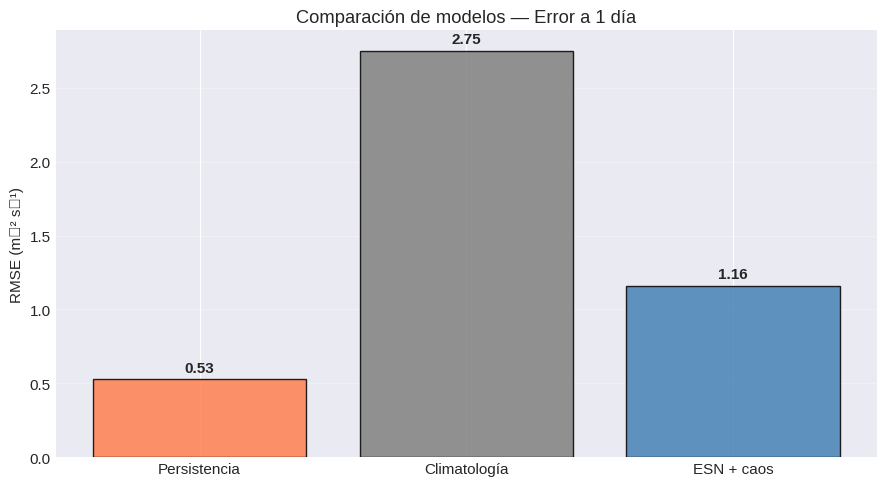

  ✓ Guardada: fig_baselines_comparison.png


In [3]:
# ============================================
# PARTE 16: BASELINES (persistencia y climatología)
# ============================================
print("\n" + "="*70)
print("PARTE 16: Comparación contra baselines")
print("="*70)

# --- Baseline 1: Persistencia ---
# rate(t+H) = rate(t)
y_persist = test['rate_mean'].values[:-1]           # pred: valor del día t
y_real_p  = test['rate_mean'].values[1:]            # real del día t+1 (H=1)
rmse_p_h1 = np.sqrt(np.mean((y_persist - y_real_p)**2))
r_p_h1    = np.corrcoef(y_persist, y_real_p)[0,1]
print(f"\n  [Baseline Persistencia, H=1 día]")
print(f"    RMSE = {rmse_p_h1:.2f}  |  r = {r_p_h1:.4f}")

# --- Baseline 2: Climatología ---
# rate(t+H) = <rate> del train
clim_value = train['rate_mean'].mean()
y_clim = np.full(len(test), clim_value)
rmse_clim_all = np.sqrt(mean_squared_error(test['rate_mean'].values, y_clim))
print(f"\n  [Baseline Climatología]")
print(f"    <rate>_train = {clim_value:.2f} m⁻² s⁻¹")
print(f"    RMSE = {rmse_clim_all:.2f}")

# --- ESN (ya calculado en Parte 13) ---
print(f"\n  [ESN + caos, H=1 día (test 20%)]")
print(f"    RMSE = {rmse:.2f}  |  r = {r_corr:.4f}")

# --- Comparación ---
print(f"\n  → Mejora relativa del ESN vs Persistencia: "
      f"{(1 - rmse/rmse_p_h1)*100:.1f}%")
print(f"  → Mejora relativa del ESN vs Climatología: "
      f"{(1 - rmse/rmse_clim_all)*100:.1f}%")

# --- Tabla resumen visual ---
fig, ax = plt.subplots(figsize=(9, 5))
names = ['Persistencia', 'Climatología', 'ESN + caos']
vals  = [rmse_p_h1, rmse_clim_all, rmse]
colors= ['coral', 'gray', 'steelblue']
bars = ax.bar(names, vals, color=colors, edgecolor='black', alpha=0.85)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width()/2, v + 0.05, f'{v:.2f}',
            ha='center', fontsize=11, fontweight='bold')
ax.set_ylabel('RMSE (m⁻² s⁻¹)')
ax.set_title('Comparación de modelos — Error a 1 día')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('fig_baselines_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("  ✓ Guardada: fig_baselines_comparison.png")